# Notebook B — identification

## Setup 1 — install

In [1]:
!pip install -q "transformers<5" datasets accelerate peft evaluate \
    jiwer sacrebleu librosa soundfile pyloudnorm openpyxl joblib scikit-learn pandas
print("ok")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 97.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 74.5 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 88.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 7.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, bu

## Setup 2 — write code files

In [2]:
%%writefile /kaggle/working/common.py
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np

REGSPEECH_ROOT = Path("/kaggle/input/datasets/mdrezuwanhassan/regspeech12")
COMMONVOICE_ROOT = Path("/kaggle/input/datasets/rithikdebnath548/bangla-common-voice-validated")
CV_CLIPS = COMMONVOICE_ROOT / "validated_clips"
CV_TSV = COMMONVOICE_ROOT / "validated.tsv"

WORK = Path("/kaggle/working")
PROC_DIR = WORK / "processed"
MANIFEST_DIR = WORK / "manifests"
CKPT_DIR = WORK / "ckpt"
STATS_PATH = WORK / "dataset_stats.json"

DIALECTS = ["standard", "chittagong", "mymensingh", "barishal", "sylhet", "noakhali"]
LABEL2ID = {d: i for i, d in enumerate(DIALECTS)}
ID2LABEL = {i: d for d, i in LABEL2ID.items()}

# kishoreganj stands in for mymensingh (Greater Mymensingh district)
REGION_MAP = {
    "chittagong":  "chittagong",
    "kishoreganj": "mymensingh",
    "barishal":    "barishal",
    "sylhet":      "sylhet",
    "noakhali":    "noakhali",
}

SR = 16000
MIN_DUR = 2.0
MAX_DUR = 20.0
ADI_CROP = 8.0
TARGET_LUFS = -23.0

MAX_CLIPS_PER_DIALECT = 1200
CV_STANDARD_CLIPS = 1200


USE_OFFICIAL_SPLITS = False
BLOCK_SIZE = 25
TRAIN_FRAC, VAL_FRAC = 0.8, 0.1
SEED = 1337

FILENAME_RE = re.compile(r"^(train|valid|test)_(.+?)_(\d+)\.wav$")


def parse_filename(name):
    m = FILENAME_RE.match(Path(name).name)
    return (m.group(1), m.group(2), int(m.group(3))) if m else None


def block_split(region, idx, block_size=BLOCK_SIZE):
    b = int(hashlib.md5(f"{region}_{idx // block_size}".encode()).hexdigest(), 16) % 10
    return "train" if b < 8 else ("val" if b == 8 else "test")


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


def ensure_dirs():
    for d in (PROC_DIR, MANIFEST_DIR, CKPT_DIR):
        d.mkdir(parents=True, exist_ok=True)


def write_manifest(rows, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"wrote {len(rows)} rows -> {path}")


def read_manifest(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]


def normalize_bangla_text(s):
    if s is None:
        return ""
    s = str(s).strip().replace("<>", " ")
    s = re.sub(r"\s+", " ", s)
    return re.sub(r"[\"'`~^*_=+\[\]{}]", "", s).strip()


def class_weights(labels, n_classes=len(DIALECTS)):
    counts = np.bincount(np.asarray(labels), minlength=n_classes).astype(float)
    counts[counts == 0] = 1.0
    w = counts.sum() / (n_classes * counts)
    return w / w.mean()


def latest_checkpoint(dirpath):
    d = Path(dirpath)
    if not d.exists():
        return None
    cks = [p for p in d.glob("checkpoint-*") if p.is_dir()]
    return str(max(cks, key=lambda p: int(p.name.split("-")[-1]))) if cks else None


def load_stats():
    return json.loads(STATS_PATH.read_text()) if STATS_PATH.exists() else {}


def gpu_report():
    try:
        import torch
        if not torch.cuda.is_available():
            print("NO GPU — Settings -> Accelerator -> GPU T4 x2")
            return
        for i in range(torch.cuda.device_count()):
            p = torch.cuda.get_device_properties(i)
            print(f"GPU {i}: {p.name}, {p.total_memory/1e9:.1f} GB")
    except ImportError:
        print("torch not installed")


Overwriting /kaggle/working/common.py


In [3]:
%%writefile /kaggle/working/viz.py

import sys
from pathlib import Path

sys.path.insert(0, "/kaggle/working")

import numpy as np
import pandas as pd
import matplotlib

try:
    get_ipython()                       
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
    matplotlib.use("Agg")

import matplotlib.pyplot as plt

if IN_NOTEBOOK:
    from IPython.display import display, Markdown

W = Path("/kaggle/working")
FIGDIR = W / "figures"
TABDIR = W / "tables"
FIGDIR.mkdir(parents=True, exist_ok=True)
TABDIR.mkdir(parents=True, exist_ok=True)

SHOW_FIGS = True
SHOW_TABLES = True
TABLE_ROWS = 15

BLUE, ORANGE, GREEN, RED, PURPLE, GREY = (
    "#2a6ebb", "#e8a33d", "#4c9a68", "#d1495b", "#7b5aa6", "#c9c9c9")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})


def new_fig(w=7.5, h=4.5):
    fig, ax = plt.subplots(figsize=(w, h))
    return fig, ax


def save_fig(fig, name, show=None):
    p = FIGDIR / f"{name}.png"
    fig.savefig(p, bbox_inches="tight")
    show = SHOW_FIGS if show is None else show
    if IN_NOTEBOOK and show:
        display(Markdown(f"**figures/{name}.png**"))
        display(fig)
    else:
        print(f"  fig  -> {p}")
    plt.close(fig)
    return p


def save_table(data, name, index=False, show=None):
    df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
    p = TABDIR / f"{name}.csv"
    df.to_csv(p, index=index)
    show = SHOW_TABLES if show is None else show
    if IN_NOTEBOOK and show:
        display(Markdown(f"**tables/{name}.csv** &nbsp; ({len(df)} rows)"))
        display(df.head(TABLE_ROWS))
        if len(df) > TABLE_ROWS:
            display(Markdown(f"*...{len(df)-TABLE_ROWS} more rows in the CSV*"))
    else:
        print(f"  csv  -> {p}  ({len(df)} rows)")
    return p


def heatmap(mat, xlabels, ylabels, title, name, cmap="Blues", fmt="{:.2f}",
            vmin=0, vmax=1, xlabel=None, ylabel=None, counts=None):
    fig, ax = plt.subplots(figsize=(max(5.5, len(xlabels) * 0.95),
                                    max(4.5, len(ylabels) * 0.8)))
    ax.grid(False)
    im = ax.imshow(mat, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(xlabels))); ax.set_yticks(range(len(ylabels)))
    ax.set_xticklabels(xlabels, rotation=45, ha="right", fontsize=9)
    ax.set_yticklabels(ylabels, fontsize=9)
    for i in range(len(ylabels)):
        for j in range(len(xlabels)):
            v = mat[i][j]
            if counts is not None:
                if counts[i][j] == 0:
                    continue
                txt = f"{fmt.format(v)}\n({int(counts[i][j])})"
            else:
                txt = fmt.format(v)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if v > (vmin + vmax) / 2 else "#222")
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, fraction=0.046)
    return save_fig(fig, name)


def prf_from_cm(cm):
    cm = np.asarray(cm, dtype=float)
    support = cm.sum(1)
    tp = np.diag(cm)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(support, 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    return prec, rec, f1, support.astype(int)


def section(title):
    if IN_NOTEBOOK:
        display(Markdown(f"### {title}"))
    else:
        print("\n" + "=" * 60 + f"\n{title}\n" + "=" * 60)

Overwriting /kaggle/working/viz.py


In [4]:
%%writefile /kaggle/working/04_train_acoustic.py
"""Automatic Dialect Identification on audio. XLS-R-300M + classification head."""
import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import (MANIFEST_DIR, CKPT_DIR, DIALECTS, LABEL2ID, ID2LABEL, SR,
                    ADI_CROP, read_manifest, set_seed, latest_checkpoint,
                    gpu_report, class_weights)

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset
import soundfile as sf
from transformers import (AutoFeatureExtractor, AutoModelForAudioClassification,
                          TrainingArguments, Trainer)
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report)

MODEL_ID = "facebook/wav2vec2-xls-r-300m"
OUT_DIR = CKPT_DIR / "dialect_id"
RESUME_FROM = None

FREEZE_BOTTOM_LAYERS = 0
EPOCHS = 15
BATCH = 4
GRAD_ACCUM = 8
LR = 1e-4


class ClipDataset(Dataset):
    def __init__(self, manifest, fe, crop=ADI_CROP, train=False):
        self.rows = read_manifest(manifest)
        self.fe, self.crop, self.train = fe, int(crop * SR), train
        print(f"{Path(manifest).name}: {len(self.rows)} clips")

    def __len__(self):
        return len(self.rows)

    def _augment(self, y):
        if np.random.rand() < 0.5:
            snr = np.random.uniform(10, 30)
            n = np.random.randn(len(y)).astype(np.float32)
            n *= np.sqrt((np.mean(y ** 2) + 1e-9) / (10 ** (snr / 10)))
            y = y + n
        if np.random.rand() < 0.3:
            y = y * np.random.uniform(0.7, 1.3)
        return np.clip(y, -1.0, 1.0)

    def __getitem__(self, i):
        r = self.rows[i]
        y, _ = sf.read(r["audio"], dtype="float32")
        if y.ndim > 1:
            y = y.mean(axis=1)
        if len(y) > self.crop:
            s = (np.random.randint(0, len(y) - self.crop) if self.train
                 else (len(y) - self.crop) // 2)
            y = y[s:s + self.crop]
        if self.train:
            y = self._augment(y)
        out = self.fe(y, sampling_rate=SR, return_tensors="np")
        return {"input_values": out["input_values"][0].astype(np.float32),
                "labels": int(r["label"])}


def collate(batch):
    m = max(len(b["input_values"]) for b in batch)
    x = np.zeros((len(batch), m), dtype=np.float32)
    mask = np.zeros((len(batch), m), dtype=np.int64)
    for i, b in enumerate(batch):
        L = len(b["input_values"])
        x[i, :L] = b["input_values"]; mask[i, :L] = 1
    return {"input_values": torch.from_numpy(x),
            "attention_mask": torch.from_numpy(mask),
            "labels": torch.tensor([b["labels"] for b in batch], dtype=torch.long)}


class WeightedTrainer(Trainer):
    def __init__(self, class_w=None, **kw):
        super().__init__(**kw)
        self.class_w = class_w

    def compute_loss(self, model, inputs, return_outputs=False, **kw):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.class_w.to(outputs.logits.device) if self.class_w is not None else None
        loss = nn.CrossEntropyLoss(weight=w)(
            outputs.logits.view(-1, len(DIALECTS)), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def metrics_fn(pred):
    logits, labels = pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p),
            "macro_f1": f1_score(labels, p, average="macro", zero_division=0)}


def main():
    set_seed(); gpu_report()

    fe = AutoFeatureExtractor.from_pretrained(MODEL_ID)
    model = AutoModelForAudioClassification.from_pretrained(
        MODEL_ID, num_labels=len(DIALECTS), label2id=LABEL2ID, id2label=ID2LABEL)
    model.freeze_feature_encoder()
    if FREEZE_BOTTOM_LAYERS:
        for layer in model.wav2vec2.encoder.layers[:FREEZE_BOTTOM_LAYERS]:
            for p in layer.parameters():
                p.requires_grad = False
    print(f"trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6:.1f}M")

    train_ds = ClipDataset(MANIFEST_DIR / "train.jsonl", fe, train=True)
    val_ds = ClipDataset(MANIFEST_DIR / "val.jsonl", fe, train=False)

    w = torch.tensor(class_weights([r["label"] for r in train_ds.rows]),
                     dtype=torch.float)
    print("class weights:", {d: round(float(x), 3) for d, x in zip(DIALECTS, w)})

    args = TrainingArguments(
        output_dir=str(OUT_DIR),
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=BATCH,
        gradient_accumulation_steps=GRAD_ACCUM,
        num_train_epochs=EPOCHS, learning_rate=LR, warmup_ratio=0.1,
        fp16=False, gradient_checkpointing=False,
        eval_strategy="epoch",
        save_strategy="epoch", save_total_limit=2, logging_steps=20,
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        greater_is_better=True, dataloader_num_workers=2, report_to="none")

    trainer = WeightedTrainer(class_w=w, model=model, args=args,
                              train_dataset=train_ds, eval_dataset=val_ds,
                              data_collator=collate, compute_metrics=metrics_fn)

    resume = RESUME_FROM or latest_checkpoint(OUT_DIR)
    if resume:
        print("resuming from", resume)
    trainer.train(resume_from_checkpoint=resume)

    Path("/kaggle/working/trainlog_acoustic.json").write_text(
        json.dumps(trainer.state.log_history, indent=2))
    trainer.save_model(str(OUT_DIR / "final"))
    fe.save_pretrained(str(OUT_DIR / "final"))

    test_ds = ClipDataset(MANIFEST_DIR / "test.jsonl", fe, train=False)
    out = trainer.predict(test_ds)
    preds, labels = np.argmax(out.predictions, axis=-1), out.label_ids
    cm = confusion_matrix(labels, preds).tolist()
    res = {"accuracy": float(accuracy_score(labels, preds)),
           "macro_f1": float(f1_score(labels, preds, average="macro", zero_division=0)),
           "confusion_matrix": cm, "labels": DIALECTS}
    print(classification_report(labels, preds, target_names=DIALECTS,
                                zero_division=0))
    for name, row in zip(DIALECTS, cm):
        print(f"  {name:12s} {row}")
    Path("/kaggle/working/dialect_id_results.json").write_text(json.dumps(res, indent=2))
    print("\ncompare macro-F1 against the shortcut probe; check the noakhali row")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/04_train_acoustic.py


In [5]:
%%writefile /kaggle/working/05_acoustic_probs.py
"""TIER 1 (acoustic) — dump per-clip probabilities from the trained XLS-R model.
No training. ~10 min on T4."""
import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import (MANIFEST_DIR, CKPT_DIR, DIALECTS, SR, ADI_CROP,
                    read_manifest, gpu_report)

import numpy as np
import torch
import soundfile as sf
from transformers import AutoFeatureExtractor, AutoModelForAudioClassification
from sklearn.metrics import accuracy_score, f1_score

MODEL_DIR = CKPT_DIR / "dialect_id" / "final"
OUT = Path("/kaggle/working/probs_acoustic.npz")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def main():
    gpu_report()
    fe = AutoFeatureExtractor.from_pretrained(str(MODEL_DIR))
    model = AutoModelForAudioClassification.from_pretrained(
        str(MODEL_DIR)).to(DEVICE).eval()

    rows = read_manifest(MANIFEST_DIR / "test.jsonl")
    crop = int(ADI_CROP * SR)
    probs, labels, paths = [], [], []

    for i, r in enumerate(rows):
        y, _ = sf.read(r["audio"], dtype="float32")
        if y.ndim > 1:
            y = y.mean(axis=1)
        if len(y) > crop:
            s = (len(y) - crop) // 2
            y = y[s:s + crop]
        inp = fe(y, sampling_rate=SR, return_tensors="pt")
        with torch.no_grad():
            logits = model(inp.input_values.to(DEVICE)).logits
        probs.append(torch.softmax(logits, -1)[0].cpu().numpy())
        labels.append(r["label"])
        paths.append(r["audio"])
        if (i + 1) % 200 == 0:
            print(f"  {i+1}/{len(rows)}")

    probs = np.stack(probs)
    labels = np.array(labels)
    pred = probs.argmax(1)
    acc = accuracy_score(labels, pred)
    f1 = f1_score(labels, pred, average="macro", zero_division=0)
    print(f"\nACOUSTIC  acc {acc:.4f}  macro-F1 {f1:.4f}")

    np.savez_compressed(OUT, probs=probs, labels=labels, paths=np.array(paths))
    Path("/kaggle/working/tier_acoustic_results.json").write_text(
        json.dumps({"tier": "acoustic", "model": "xls-r-300m",
                    "accuracy": float(acc), "macro_f1": float(f1),
                    "n": int(len(labels))}, indent=2))
    print(f"saved -> {OUT}")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/05_acoustic_probs.py


In [6]:
%%writefile /kaggle/working/06_train_phonotactic.py
"""TIER 2 (phonotactic) — quantize audio into discrete units, classify the
token sequence. Acoustic detail is discarded; only sound ORDER survives."""
import sys, json, collections
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import (MANIFEST_DIR, DIALECTS, SR, ADI_CROP, read_manifest,
                    set_seed, gpu_report, class_weights)

import numpy as np
import torch
import torch.nn as nn
import soundfile as sf
from torch.utils.data import Dataset, DataLoader
from sklearn.cluster import MiniBatchKMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

SSL_MODEL = "facebook/wav2vec2-xls-r-300m"
LAYER = 15
K = 200
DEDUP = True
MAX_LEN = 400

FEAT_DIR = Path("/kaggle/working/units")
OUT = Path("/kaggle/working/probs_phonotactic.npz")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EPOCHS = 25
BATCH = 32
LR = 3e-4
D_MODEL = 256
N_LAYERS = 4
N_HEADS = 4


# ---------------------------------------------------------------- A. features
def extract_features():
    from transformers import AutoFeatureExtractor, AutoModel
    FEAT_DIR.mkdir(parents=True, exist_ok=True)
    fe = AutoFeatureExtractor.from_pretrained(SSL_MODEL)
    model = AutoModel.from_pretrained(SSL_MODEL).to(DEVICE).eval()
    crop = int(ADI_CROP * SR)

    for split in ("train", "val", "test"):
        out_path = FEAT_DIR / f"{split}_feats.npz"
        if out_path.exists():
            print(f"{split}: cached"); continue
        rows = read_manifest(MANIFEST_DIR / f"{split}.jsonl")
        feats, labels, paths, lengths = [], [], [], []
        for i, r in enumerate(rows):
            y, _ = sf.read(r["audio"], dtype="float32")
            if y.ndim > 1:
                y = y.mean(axis=1)
            if len(y) > crop:
                s = (len(y) - crop) // 2
                y = y[s:s + crop]
            inp = fe(y, sampling_rate=SR, return_tensors="pt")
            with torch.no_grad():
                h = model(inp.input_values.to(DEVICE),
                          output_hidden_states=True).hidden_states[LAYER]
            f = h[0].cpu().numpy().astype(np.float16)
            feats.append(f); lengths.append(len(f))
            labels.append(r["label"]); paths.append(r["audio"])
            if (i + 1) % 200 == 0:
                print(f"  {split} {i+1}/{len(rows)}")
        np.savez_compressed(out_path,
                            feats=np.concatenate(feats, 0),
                            lengths=np.array(lengths),
                            labels=np.array(labels),
                            paths=np.array(paths))
        print(f"saved {out_path}")


def load_split(split):
    z = np.load(FEAT_DIR / f"{split}_feats.npz", allow_pickle=True)
    feats, lengths = z["feats"], z["lengths"]
    offs = np.concatenate([[0], np.cumsum(lengths)])
    seqs = [feats[offs[i]:offs[i + 1]] for i in range(len(lengths))]
    return seqs, z["labels"], z["paths"]


# ---------------------------------------------------------------- B. k-means
def fit_kmeans(train_seqs):
    path = FEAT_DIR / f"kmeans_{K}.npy"
    if path.exists():
        print("k-means: cached")
        return np.load(path)
    X = np.concatenate(train_seqs, 0).astype(np.float32)
    idx = np.random.choice(len(X), min(300000, len(X)), replace=False)
    km = MiniBatchKMeans(n_clusters=K, batch_size=10000, n_init=5,
                         max_iter=200, random_state=0, verbose=0)
    km.fit(X[idx])
    np.save(path, km.cluster_centers_)
    print(f"k-means fitted on {len(idx)} frames -> {K} units")
    return km.cluster_centers_


def quantize(seqs, centers):
    C = torch.tensor(centers, dtype=torch.float32, device=DEVICE)
    Cn = (C ** 2).sum(1)
    out = []
    for s in seqs:
        X = torch.tensor(s.astype(np.float32), device=DEVICE)
        d = (X ** 2).sum(1, keepdim=True) - 2 * X @ C.T + Cn
        u = d.argmin(1).cpu().numpy()
        if DEDUP:
            keep = np.concatenate([[True], u[1:] != u[:-1]])
            u = u[keep]
        out.append(u[:MAX_LEN])
    return out


# ---------------------------------------------------------------- C. n-grams
def ngram_classifier(tr_u, tr_y, te_u, te_y):
    to_str = lambda us: [" ".join(f"u{v}" for v in u) for u in us]
    vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 4),
                          min_df=3, max_features=200000, sublinear_tf=True)
    Xtr = vec.fit_transform(to_str(tr_u))
    Xte = vec.transform(to_str(te_u))
    clf = LogisticRegression(max_iter=3000, C=5.0, class_weight="balanced")
    clf.fit(Xtr, tr_y)
    probs = clf.predict_proba(Xte)
    pred = probs.argmax(1)
    acc = accuracy_score(te_y, pred)
    f1 = f1_score(te_y, pred, average="macro", zero_division=0)
    print(f"\nPHONOTACTIC (n-gram)  acc {acc:.4f}  macro-F1 {f1:.4f}")
    print(classification_report(te_y, pred, target_names=DIALECTS,
                                zero_division=0))

    names = np.array(vec.get_feature_names_out())
    top = {}
    for i, d in enumerate(DIALECTS):
        w = clf.coef_[i] if clf.coef_.shape[0] > 1 else clf.coef_[0]
        order = np.argsort(w)[::-1][:15]
        top[d] = [(names[j], float(w[j])) for j in order]
        print(f"  {d:12s} top units: {', '.join(names[j] for j in order[:6])}")
    Path("/kaggle/working/phonotactic_top_ngrams.json").write_text(
        json.dumps(top, indent=2))
    return probs, acc, f1


# ---------------------------------------------------------------- D. transformer
class UnitDS(Dataset):
    def __init__(self, units, labels, train=False):
        self.u, self.y, self.train = units, labels, train

    def __len__(self):
        return len(self.u)

    def __getitem__(self, i):
        u = self.u[i]
        if self.train and len(u) > 32:
            n = np.random.randint(0, max(1, len(u) // 10))
            if n:
                keep = np.ones(len(u), bool)
                keep[np.random.choice(len(u), n, replace=False)] = False
                u = u[keep]
        return torch.tensor(u, dtype=torch.long), int(self.y[i])


def pad_collate(batch):
    xs, ys = zip(*batch)
    m = max(len(x) for x in xs)
    out = torch.zeros(len(xs), m, dtype=torch.long)
    mask = torch.zeros(len(xs), m, dtype=torch.bool)
    for i, x in enumerate(xs):
        out[i, :len(x)] = x + 1
        mask[i, len(x):] = True
    return out, mask, torch.tensor(ys, dtype=torch.long)


class UnitTransformer(nn.Module):
    def __init__(self, vocab=K + 1, d=D_MODEL, n_layers=N_LAYERS, n_heads=N_HEADS,
                 n_cls=len(DIALECTS), max_len=MAX_LEN + 2):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.pos = nn.Embedding(max_len, d)
        enc = nn.TransformerEncoderLayer(d, n_heads, d * 4, 0.1,
                                         batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(enc, n_layers)
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_cls)

    def forward(self, x, mask):
        p = torch.arange(x.size(1), device=x.device).unsqueeze(0)
        h = self.emb(x) + self.pos(p)
        h = self.enc(h, src_key_padding_mask=mask)
        h = self.norm(h)
        valid = (~mask).unsqueeze(-1).float()
        pooled = (h * valid).sum(1) / valid.sum(1).clamp(min=1)
        return self.head(pooled)


def transformer_classifier(tr_u, tr_y, va_u, va_y, te_u, te_y):
    set_seed()
    model = UnitTransformer().to(DEVICE)
    w = torch.tensor(class_weights(tr_y), dtype=torch.float, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, LR, epochs=EPOCHS,
        steps_per_epoch=max(1, len(tr_u) // BATCH + 1))

    dl_tr = DataLoader(UnitDS(tr_u, tr_y, True), BATCH, shuffle=True,
                       collate_fn=pad_collate)
    dl_va = DataLoader(UnitDS(va_u, va_y), BATCH, collate_fn=pad_collate)
    dl_te = DataLoader(UnitDS(te_u, te_y), BATCH, collate_fn=pad_collate)

    best, best_state, hist = -1, None, []
    for ep in range(EPOCHS):
        model.train()
        tot = 0
        for x, m, y in dl_tr:
            x, m, y = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
            loss = crit(model(x, m), y)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item()
        model.eval()
        P, Y = [], []
        with torch.no_grad():
            for x, m, y in dl_va:
                P.append(model(x.to(DEVICE), m.to(DEVICE)).argmax(1).cpu().numpy())
                Y.append(y.numpy())
        f1 = f1_score(np.concatenate(Y), np.concatenate(P),
                      average="macro", zero_division=0)
        print(f"  ep {ep+1:2d}  loss {tot/len(dl_tr):.4f}  val macro-F1 {f1:.4f}")
        hist.append({"epoch": ep + 1, "train_loss": tot / len(dl_tr),
                     "val_macro_f1": float(f1)})
        if f1 > best:
            best = f1
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}

    Path("/kaggle/working/trainlog_phonotactic.json").write_text(
        json.dumps(hist, indent=2))
    model.load_state_dict(best_state)
    model.eval()
    P, Y = [], []
    with torch.no_grad():
        for x, m, y in dl_te:
            P.append(torch.softmax(model(x.to(DEVICE), m.to(DEVICE)), -1).cpu().numpy())
            Y.append(y.numpy())
    probs = np.concatenate(P); Y = np.concatenate(Y)
    pred = probs.argmax(1)
    acc = accuracy_score(Y, pred)
    f1 = f1_score(Y, pred, average="macro", zero_division=0)
    print(f"\nPHONOTACTIC (transformer)  acc {acc:.4f}  macro-F1 {f1:.4f}")
    print(classification_report(Y, pred, target_names=DIALECTS, zero_division=0))
    return probs, acc, f1


def main():
    gpu_report(); set_seed()
    extract_features()

    tr_seqs, tr_y, _ = load_split("train")
    va_seqs, va_y, _ = load_split("val")
    te_seqs, te_y, te_paths = load_split("test")

    centers = fit_kmeans(tr_seqs)
    tr_u = quantize(tr_seqs, centers)
    va_u = quantize(va_seqs, centers)
    te_u = quantize(te_seqs, centers)
    print(f"mean unit-sequence length: {np.mean([len(u) for u in tr_u]):.0f}")

    p_ng, a_ng, f_ng = ngram_classifier(tr_u, tr_y, te_u, te_y)
    p_tf, a_tf, f_tf = transformer_classifier(tr_u, tr_y, va_u, va_y, te_u, te_y)

    use_tf = f_tf >= f_ng
    probs = p_tf if use_tf else p_ng
    print(f"\nusing {'transformer' if use_tf else 'n-gram'} as the phonotactic tier")

    np.savez_compressed(OUT, probs=probs, labels=te_y, paths=te_paths)
    Path("/kaggle/working/tier_phonotactic_results.json").write_text(json.dumps({
        "tier": "phonotactic", "k_units": K, "layer": LAYER, "dedup": DEDUP,
        "ngram": {"accuracy": float(a_ng), "macro_f1": float(f_ng)},
        "transformer": {"accuracy": float(a_tf), "macro_f1": float(f_tf)},
        "selected": "transformer" if use_tf else "ngram"}, indent=2))
    print(f"saved -> {OUT}")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/06_train_phonotactic.py


In [7]:
%%writefile /kaggle/working/07_train_lexical.py
"""TIER 3 (lexical) — classify from TEXT. Detects dialect-specific vocabulary
and morphology; phonetic detail is gone."""
import sys, json, argparse, collections
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import (MANIFEST_DIR, CKPT_DIR, DIALECTS, SR, read_manifest,
                    normalize_bangla_text, set_seed, gpu_report, class_weights)

import numpy as np
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

TEXT_MODEL = "csebuetnlp/banglabert"
EPOCHS = 6
BATCH = 16
LR = 2e-5
MAX_TOK = 128
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ASR_DIR = CKPT_DIR / "asr_prompt" / "all" / "final"


def get_rows(split, source="gold"):
    rows = read_manifest(MANIFEST_DIR / f"{split}.jsonl")
    if source == "gold":
        return [r for r in rows if r.get("text")]
    cache = Path(f"/kaggle/working/asr_text_{split}.json")
    if cache.exists():
        got = json.loads(cache.read_text())
        out = []
        for r in rows:
            if r["audio"] in got:
                r = dict(r); r["text"] = got[r["audio"]]
                out.append(r)
        return out
    return transcribe(rows, split, cache)


def transcribe(rows, split, cache):
    from transformers import WhisperProcessor, WhisperForConditionalGeneration
    import soundfile as sf
    if not ASR_DIR.exists():
        raise SystemExit(f"{ASR_DIR} missing — run 05_train_asr.py or use gold")
    p = WhisperProcessor.from_pretrained(str(ASR_DIR))
    base = WhisperForConditionalGeneration.from_pretrained("openai/whisper-small")
    if (ASR_DIR / "adapter_config.json").exists():
        from peft import PeftModel
        m = PeftModel.from_pretrained(base, str(ASR_DIR))
    else:
        m = WhisperForConditionalGeneration.from_pretrained(str(ASR_DIR))
    m = m.to(DEVICE).eval()
    m.generation_config.language = "bengali"
    m.generation_config.task = "transcribe"

    got, out = {}, []
    for i, r in enumerate(rows):
        y, _ = sf.read(r["audio"], dtype="float32")
        if y.ndim > 1:
            y = y.mean(axis=1)
        feats = p.feature_extractor(y, sampling_rate=SR,
                                    return_tensors="pt").input_features.to(DEVICE)
        with torch.no_grad():
            ids = m.generate(feats, max_length=225)
        t = p.batch_decode(ids, skip_special_tokens=True)[0]
        for d in DIALECTS:
            t = t.replace(f"<{d}>", "")
        t = normalize_bangla_text(t)
        got[r["audio"]] = t
        r = dict(r); r["text"] = t
        out.append(r)
        if (i + 1) % 100 == 0:
            print(f"  transcribed {i+1}/{len(rows)}")
    cache.write_text(json.dumps(got, ensure_ascii=False))
    return out


def char_ngram(tr, te):
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 5),
                          min_df=2, max_features=300000, sublinear_tf=True)
    Xtr = vec.fit_transform([r["text"] for r in tr])
    Xte = vec.transform([r["text"] for r in te])
    ytr = np.array([r["label"] for r in tr])
    yte = np.array([r["label"] for r in te])
    clf = LogisticRegression(max_iter=3000, C=5.0, class_weight="balanced")
    clf.fit(Xtr, ytr)
    probs = clf.predict_proba(Xte)
    pred = probs.argmax(1)
    acc = accuracy_score(yte, pred)
    f1 = f1_score(yte, pred, average="macro", zero_division=0)
    print(f"\nLEXICAL (char n-gram)  acc {acc:.4f}  macro-F1 {f1:.4f}")
    print(classification_report(yte, pred, target_names=DIALECTS, zero_division=0))

    names = np.array(vec.get_feature_names_out())
    top = {}
    for i, d in enumerate(DIALECTS):
        w = clf.coef_[i] if clf.coef_.shape[0] > 1 else clf.coef_[0]
        order = np.argsort(w)[::-1][:20]
        top[d] = [names[j] for j in order]
        print(f"  {d:12s}: {', '.join(names[j].strip() for j in order[:6])}")
    Path("/kaggle/working/lexical_top_ngrams.json").write_text(
        json.dumps(top, indent=2, ensure_ascii=False))
    return probs, yte, acc, f1


def bert(tr, va, te):
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    from torch.utils.data import Dataset, DataLoader
    set_seed()
    tok = AutoTokenizer.from_pretrained(TEXT_MODEL)
    model = AutoModelForSequenceClassification.from_pretrained(
        TEXT_MODEL, num_labels=len(DIALECTS)).to(DEVICE)

    class DS(Dataset):
        def __init__(self, rows):
            self.r = rows

        def __len__(self):
            return len(self.r)

        def __getitem__(self, i):
            e = tok(self.r[i]["text"], truncation=True, max_length=MAX_TOK,
                    padding="max_length", return_tensors="pt")
            return ({k: v[0] for k, v in e.items()}, self.r[i]["label"])

    def coll(b):
        xs, ys = zip(*b)
        return ({k: torch.stack([x[k] for x in xs]) for k in xs[0]},
                torch.tensor(ys, dtype=torch.long))

    dl_tr = DataLoader(DS(tr), BATCH, shuffle=True, collate_fn=coll)
    dl_va = DataLoader(DS(va), BATCH, collate_fn=coll)
    dl_te = DataLoader(DS(te), BATCH, collate_fn=coll)

    w = torch.tensor(class_weights([r["label"] for r in tr]),
                     dtype=torch.float, device=DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)

    best, best_state = -1, None
    for ep in range(EPOCHS):
        model.train()
        tot = 0
        for x, y in dl_tr:
            x = {k: v.to(DEVICE) for k, v in x.items()}
            loss = crit(model(**x).logits, y.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item()
        model.eval()
        P, Y = [], []
        with torch.no_grad():
            for x, y in dl_va:
                x = {k: v.to(DEVICE) for k, v in x.items()}
                P.append(model(**x).logits.argmax(1).cpu().numpy()); Y.append(y.numpy())
        f1 = f1_score(np.concatenate(Y), np.concatenate(P),
                      average="macro", zero_division=0)
        print(f"  ep {ep+1}  loss {tot/len(dl_tr):.4f}  val macro-F1 {f1:.4f}")
        if f1 > best:
            best = f1
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}

    model.load_state_dict(best_state); model.eval()
    P, Y = [], []
    with torch.no_grad():
        for x, y in dl_te:
            x = {k: v.to(DEVICE) for k, v in x.items()}
            P.append(torch.softmax(model(**x).logits, -1).cpu().numpy())
            Y.append(y.numpy())
    probs = np.concatenate(P); Y = np.concatenate(Y)
    pred = probs.argmax(1)
    acc = accuracy_score(Y, pred)
    f1 = f1_score(Y, pred, average="macro", zero_division=0)
    print(f"\nLEXICAL (BanglaBERT)  acc {acc:.4f}  macro-F1 {f1:.4f}")
    print(classification_report(Y, pred, target_names=DIALECTS, zero_division=0))
    return probs, Y, acc, f1


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--source", default="gold", choices=["gold", "asr"])
    ap.add_argument("--skip-bert", action="store_true")
    a = ap.parse_args()
    gpu_report()
    print(f"text source: {a.source}")

    tr = get_rows("train", a.source)
    va = get_rows("val", a.source)
    te = get_rows("test", a.source)
    print(f"train {len(tr)}  val {len(va)}  test {len(te)}")
    print("per dialect (test):",
          dict(collections.Counter(r["dialect"] for r in te)))

    p_ng, y, a_ng, f_ng = char_ngram(tr, te)
    if a.skip_bert:
        probs, acc, f1, sel = p_ng, a_ng, f_ng, "char_ngram"
        a_bt = f_bt = None
    else:
        p_bt, y2, a_bt, f_bt = bert(tr, va, te)
        use = f_bt >= f_ng
        probs, acc, f1 = (p_bt, a_bt, f_bt) if use else (p_ng, a_ng, f_ng)
        sel = "banglabert" if use else "char_ngram"
    print(f"\nusing {sel} as the lexical tier")

    paths = np.array([r["audio"] for r in te])
    np.savez_compressed(f"/kaggle/working/probs_lexical_{a.source}.npz",
                        probs=probs, labels=y, paths=paths)
    Path(f"/kaggle/working/tier_lexical_{a.source}_results.json").write_text(
        json.dumps({"tier": "lexical", "source": a.source, "selected": sel,
                    "char_ngram": {"accuracy": float(a_ng), "macro_f1": float(f_ng)},
                    "banglabert": None if a_bt is None else
                    {"accuracy": float(a_bt), "macro_f1": float(f_bt)},
                    "n": int(len(y))}, indent=2))
    print(f"saved -> /kaggle/working/probs_lexical_{a.source}.npz")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/07_train_lexical.py


In [8]:
%%writefile /kaggle/working/08_compare_fusion.py
"""Compare the three tiers, fuse them and plot."""
import sys, json, itertools
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from common import DIALECTS

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report)

W = Path("/kaggle/working")
TIERS = {"acoustic": "probs_acoustic.npz",
         "phonotactic": "probs_phonotactic.npz",
         "lexical": "probs_lexical_gold.npz"}
if (W / "probs_lexical_asr.npz").exists():
    TIERS["lexical (ASR)"] = "probs_lexical_asr.npz"


def load():
    out = {}
    for name, f in TIERS.items():
        p = W / f
        if not p.exists():
            print(f"missing {f} — skipping {name}"); continue
        z = np.load(p, allow_pickle=True)
        out[name] = {"probs": z["probs"], "labels": z["labels"],
                     "paths": np.array([str(x) for x in z["paths"]])}
    return out


def align(tiers):
    """Intersect on audio path; the lexical tier drops clips without text."""
    common = None
    for t in tiers.values():
        s = set(t["paths"])
        common = s if common is None else (common & s)
    common = sorted(common)
    print(f"clips shared by all tiers: {len(common)}")
    idx = {p: i for i, p in enumerate(common)}
    out = {}
    for name, t in tiers.items():
        P = np.zeros((len(common), len(DIALECTS)))
        Y = np.zeros(len(common), dtype=int)
        for j, path in enumerate(t["paths"]):
            if path in idx:
                P[idx[path]] = t["probs"][j]
                Y[idx[path]] = t["labels"][j]
        out[name] = P
    return out, Y, common


def score(P, Y):
    pred = P.argmax(1)
    return {"accuracy": float(accuracy_score(Y, pred)),
            "macro_f1": float(f1_score(Y, pred, average="macro", zero_division=0)),
            "per_class_f1": f1_score(Y, pred, average=None,
                                     labels=range(len(DIALECTS)),
                                     zero_division=0).tolist()}


def main():
    tiers = load()
    if len(tiers) < 2:
        raise SystemExit("need at least two tiers — run 07/08/09 first")
    P, Y, paths = align(tiers)

    core = [k for k in ("acoustic", "phonotactic", "lexical") if k in P]
    results = {k: score(P[k], Y) for k in P}

    # fusion over every subset of the three core tiers
    fusions = {}
    for r in (2, 3):
        for combo in itertools.combinations(core, r):
            name = " + ".join(combo)
            fused = np.mean([P[k] for k in combo], 0)
            fusions[name] = score(fused, Y)
    best_fusion = max(fusions, key=lambda k: fusions[k]["macro_f1"]) if fusions else None

    print("\n" + "=" * 66)
    print(f"{'system':28s} {'accuracy':>10s} {'macro-F1':>10s}")
    print("=" * 66)
    for k in P:
        print(f"{k:28s} {results[k]['accuracy']:10.4f} {results[k]['macro_f1']:10.4f}")
    print("-" * 66)
    for k, v in sorted(fusions.items(), key=lambda kv: -kv[1]["macro_f1"]):
        print(f"{'FUSE ' + k:28s} {v['accuracy']:10.4f} {v['macro_f1']:10.4f}")

    print("\nper-dialect F1 by tier")
    hdr = f"{'dialect':13s}" + "".join(f"{k[:11]:>13s}" for k in core)
    print(hdr); print("-" * len(hdr))
    for i, d in enumerate(DIALECTS):
        row = f"{d:13s}" + "".join(f"{results[k]['per_class_f1'][i]:13.3f}" for k in core)
        print(row)

    print("\ninterpretation per dialect:")
    for i, d in enumerate(DIALECTS):
        vals = {k: results[k]["per_class_f1"][i] for k in core}
        best = max(vals, key=vals.get)
        note = {"acoustic": "differs mainly in ACCENT (phonetic)",
                "phonotactic": "differs in SOUND SEQUENCES",
                "lexical": "differs in VOCABULARY / morphology"}[best]
        print(f"  {d:13s} best = {best:12s} ({vals[best]:.3f})  -> {note}")

    out = {"per_tier": results, "fusion": fusions, "best_fusion": best_fusion,
           "n_clips": len(Y), "dialects": DIALECTS}
    (W / "tier_comparison.json").write_text(json.dumps(out, indent=2))

    # ---------------------------------------------------------------- plots
    fig = plt.figure(figsize=(15, 11))
    gs = fig.add_gridspec(3, 2, hspace=0.5, wspace=0.28)
    BLUE, ORANGE, GREEN, GREY = "#2a6ebb", "#e8a33d", "#4c9a68", "#c9c9c9"
    tier_col = {"acoustic": BLUE, "phonotactic": ORANGE, "lexical": GREEN,
                "lexical (ASR)": "#8fbf9f"}

    ax = fig.add_subplot(gs[0, :])
    names = list(P) + [f"FUSE {k}" for k in fusions]
    vals = [results[k]["macro_f1"] for k in P] + \
           [fusions[k]["macro_f1"] for k in fusions]
    cols = [tier_col.get(k, GREY) for k in P] + ["#17406b"] * len(fusions)
    order = np.argsort(vals)
    b = ax.barh([names[i] for i in order], [vals[i] for i in order],
                color=[cols[i] for i in order])
    ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
    ax.axvline(1 / len(DIALECTS), ls="--", c="#444", lw=1, label="chance")
    ax.set_xlim(0, 1.08); ax.legend(fontsize=8)
    ax.set_title("Macro-F1 by system (tiers and fusions)")

    ax = fig.add_subplot(gs[1, 0])
    x = np.arange(len(DIALECTS)); w = 0.8 / len(core)
    for j, k in enumerate(core):
        ax.bar(x + (j - (len(core) - 1) / 2) * w,
               results[k]["per_class_f1"], w, label=k, color=tier_col[k])
    ax.set_xticks(x); ax.set_xticklabels(DIALECTS, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, 1.1); ax.legend(fontsize=8)
    ax.set_title("Per-dialect F1 by linguistic tier")

    ax = fig.add_subplot(gs[1, 1])
    M = np.array([results[k]["per_class_f1"] for k in core])
    im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(len(core))); ax.set_yticklabels(core, fontsize=9)
    ax.set_xticks(range(len(DIALECTS)))
    ax.set_xticklabels(DIALECTS, rotation=45, ha="right", fontsize=8)
    for i in range(len(core)):
        for j in range(len(DIALECTS)):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("Where each dialect's signal lives")
    fig.colorbar(im, ax=ax, fraction=0.046)

    ax = fig.add_subplot(gs[2, 0])
    if best_fusion:
        fused = np.mean([P[k] for k in best_fusion.split(" + ")], 0)
        cm = confusion_matrix(Y, fused.argmax(1))
        cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(len(DIALECTS))); ax.set_yticks(range(len(DIALECTS)))
        ax.set_xticklabels(DIALECTS, rotation=45, ha="right", fontsize=8)
        ax.set_yticklabels(DIALECTS, fontsize=8)
        for i in range(len(DIALECTS)):
            for j in range(len(DIALECTS)):
                if cm[i, j]:
                    ax.text(j, i, f"{cmn[i,j]:.2f}", ha="center", va="center",
                            fontsize=7, color="white" if cmn[i, j] > .5 else "#222")
        ax.set_ylabel("true"); ax.set_xlabel("predicted")
        ax.set_title(f"Best fusion: {best_fusion}")

    ax = fig.add_subplot(gs[2, 1])
    if len(core) >= 2:
        agree = np.zeros((len(core), len(core)))
        for i, a in enumerate(core):
            for j, b_ in enumerate(core):
                agree[i, j] = (P[a].argmax(1) == P[b_].argmax(1)).mean()
        im = ax.imshow(agree, cmap="Purples", vmin=0, vmax=1)
        ax.set_xticks(range(len(core))); ax.set_yticks(range(len(core)))
        ax.set_xticklabels(core, rotation=30, ha="right", fontsize=8)
        ax.set_yticklabels(core, fontsize=8)
        for i in range(len(core)):
            for j in range(len(core)):
                ax.text(j, i, f"{agree[i,j]:.2f}", ha="center", va="center",
                        fontsize=9, color="white" if agree[i, j] > .5 else "#222")
        ax.set_title("Prediction agreement between tiers\n(low = complementary)",
                     fontsize=10)

    fig.suptitle("Bangla dialect identification across three linguistic tiers",
                 fontsize=14, y=0.995)
    fig.savefig(W / "tier_comparison.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nsaved -> {W/'tier_comparison.json'} and tier_comparison.png")


if __name__ == "__main__":
    main()


Overwriting /kaggle/working/08_compare_fusion.py


In [9]:
%%writefile /kaggle/working/plot_03_acoustic.py
"""Acoustic (XLS-R) result figures + tables."""
import sys, json
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from viz import (W, new_fig, save_fig, save_table, heatmap, prf_from_cm,
                 BLUE, RED, GREEN, ORANGE, GREY)
from common import DIALECTS

import numpy as np
import pandas as pd

R = json.loads((W / "dialect_id_results.json").read_text())
cm = np.array(R["confusion_matrix"])
prec, rec, f1, sup = prf_from_cm(cm)
CHANCE = 1.0 / len(DIALECTS)

pp = W / "shortcut_probe_results.json"
P = json.loads(pp.read_text()) if pp.exists() else None
if P:
    bestp = max(P, key=lambda k: P[k]["macro_f1"])
    pa, pf = P[bestp]["accuracy"], P[bestp]["macro_f1"]
else:
    pa = pf = 0.0


# 1 --------------------------------------------------------------- confusion
save_table(pd.DataFrame(cm, index=DIALECTS, columns=DIALECTS),
           "acoustic_confusion_matrix", index=True)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
save_table(pd.DataFrame(np.round(cmn, 4), index=DIALECTS, columns=DIALECTS),
           "acoustic_confusion_normalised", index=True)
heatmap(cmn, DIALECTS, DIALECTS, "Acoustic ADI — confusion (row-normalised)",
        "09_acoustic_confusion", counts=cm, xlabel="predicted", ylabel="true")


# 2 --------------------------------------------------------------- per class
save_table([{"dialect": d, "precision": prec[i], "recall": rec[i], "f1": f1[i],
             "support": sup[i]} for i, d in enumerate(DIALECTS)],
           "acoustic_per_class")

fig, ax = new_fig(8, 4.5)
x = np.arange(len(DIALECTS)); w = 0.26
ax.bar(x - w, prec, w, label="precision", color="#7ba7d7")
ax.bar(x, rec, w, label="recall", color=BLUE)
b = ax.bar(x + w, f1, w, label="F1", color="#17406b")
ax.bar_label(b, fmt="%.2f", fontsize=7, padding=1)
ax.axhline(R["macro_f1"], ls="--", c="#444", lw=1,
           label=f"macro-F1 {R['macro_f1']:.3f}")
ax.set_xticks(x); ax.set_xticklabels(DIALECTS, rotation=45, ha="right")
ax.set_ylim(0, 1.12); ax.legend(fontsize=8)
ax.set_title("Acoustic ADI — per-class performance")
save_fig(fig, "10_acoustic_per_class")


# 3 --------------------------------------------------------- vs probe floor
save_table([{"system": "chance", "accuracy": CHANCE, "macro_f1": CHANCE},
            {"system": "shortcut probe", "accuracy": pa, "macro_f1": pf},
            {"system": "acoustic (XLS-R)", "accuracy": R["accuracy"],
             "macro_f1": R["macro_f1"]},
            {"system": "gain over probe", "accuracy": R["accuracy"] - pa,
             "macro_f1": R["macro_f1"] - pf}],
           "acoustic_vs_probe")

fig, ax = new_fig(7, 4.5)
xx = np.arange(2)
b1 = ax.bar(xx - 0.24, [CHANCE, CHANCE], 0.22, label="chance", color=GREY)
b2 = ax.bar(xx, [pa, pf], 0.22, label="shortcut probe", color=ORANGE)
b3 = ax.bar(xx + 0.24, [R["accuracy"], R["macro_f1"]], 0.22,
            label="acoustic (XLS-R)", color=BLUE)
for b in (b2, b3):
    ax.bar_label(b, fmt="%.3f", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(["accuracy", "macro-F1"])
ax.set_ylim(0, 1.15); ax.legend(fontsize=8)
ax.set_title("Learning above the corpus-sorting floor\n"
             f"macro-F1 gain over probe: {R['macro_f1']-pf:+.3f}", fontsize=10)
save_fig(fig, "11_acoustic_vs_probe")


# 4 --------------------------------------------------------------- errors
err = cm.copy(); np.fill_diagonal(err, 0)
pairs = [{"true": DIALECTS[i], "predicted": DIALECTS[j], "count": int(err[i, j])}
         for i in range(len(DIALECTS)) for j in range(len(DIALECTS)) if err[i, j] > 0]
pairs.sort(key=lambda d: -d["count"])
save_table(pairs, "acoustic_confusions_ranked")

if pairs:
    top = pairs[:10]
    fig, ax = new_fig(8, 4.5)
    labels = [f"{d['true'][:10]} -> {d['predicted'][:10]}" for d in top][::-1]
    b = ax.barh(labels, [d["count"] for d in top][::-1], color=RED)
    ax.bar_label(b, fontsize=8, padding=2)
    ax.set_xlabel("misclassified clips")
    ax.set_title("Acoustic ADI — largest confusions")
    save_fig(fig, "12_acoustic_confusions")


# 5 --------------------------------------------------------------- summary
summary = [
    ("test_clips", int(sup.sum())),
    ("accuracy", round(float(R["accuracy"]), 4)),
    ("macro_f1", round(float(R["macro_f1"]), 4)),
    ("chance", round(CHANCE, 4)),
    ("probe_macro_f1", round(pf, 4)),
    ("gain_over_probe_macro_f1", round(float(R["macro_f1"]) - pf, 4)),
    ("best_class", f"{DIALECTS[int(np.argmax(f1))]} ({f1.max():.3f})"),
    ("worst_class", f"{DIALECTS[int(np.argmin(f1))]} ({f1.min():.3f})"),
    ("worst_class_support", int(sup[int(np.argmin(f1))])),
]
save_table([{"metric": k, "value": v} for k, v in summary], "acoustic_summary")
print("\n" + "\n".join(f"  {k:28s} {v}" for k, v in summary))


Overwriting /kaggle/working/plot_03_acoustic.py


In [10]:
%%writefile /kaggle/working/plot_04_curves.py
"""Per-epoch training curves. Plots whatever has been trained so far."""
import sys, json, glob
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from viz import W, new_fig, save_fig, save_table, BLUE, ORANGE, GREEN, RED, PURPLE

import numpy as np
import pandas as pd


def load_hf(name, ckpt_glob):
    f = W / f"trainlog_{name}.json"
    if f.exists():
        return json.loads(f.read_text())
    cks = sorted(glob.glob(str(W / ckpt_glob / "checkpoint-*" / "trainer_state.json")),
                 key=lambda p: int(p.split("checkpoint-")[1].split("/")[0]))
    if cks:
        print(f"{name}: from {cks[-1]}")
        return json.loads(Path(cks[-1]).read_text()).get("log_history", [])
    return None


def series(hist, key):
    xs = [h["epoch"] for h in hist if key in h and "epoch" in h]
    ys = [h[key] for h in hist if key in h and "epoch" in h]
    return np.array(xs), np.array(ys)


def to_csv(hist, name):
    df = pd.DataFrame(hist)
    keep = [c for c in ("epoch", "step", "loss", "learning_rate", "eval_loss",
                        "eval_accuracy", "eval_macro_f1", "eval_wer", "eval_cer")
            if c in df.columns]
    if keep:
        save_table(df[keep].sort_values("epoch"), name)


acoustic = load_hf("acoustic", "ckpt/dialect_id")
asr = {m: load_hf(f"asr_{m}", f"ckpt/asr_{m}/all") for m in ("none", "prompt")}
asr = {k: v for k, v in asr.items() if v}
pho_f = W / "trainlog_phonotactic.json"
pho = json.loads(pho_f.read_text()) if pho_f.exists() else None

if not (acoustic or asr or pho):
    raise SystemExit("no training logs found")


# ------------------------------------------------------------- acoustic
if acoustic:
    to_csv(acoustic, "curve_acoustic")

    fig, ax = new_fig(7.5, 4.2)
    tx, ty = series(acoustic, "loss")
    ex, ey = series(acoustic, "eval_loss")
    if len(tx):
        ax.plot(tx, ty, color=BLUE, lw=1.2, alpha=.85, label="train loss")
    if len(ex):
        ax.plot(ex, ey, color=RED, lw=1.8, marker="o", ms=3, label="eval loss")
    ax.axhline(np.log(6), ls="--", c="#444", lw=1, label="chance ln(6) = 1.79")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(fontsize=8)
    ax.set_title("Acoustic ADI — loss")
    save_fig(fig, "13_curve_acoustic_loss")

    fig, ax = new_fig(7.5, 4.2)
    for key, col, lab in (("eval_accuracy", BLUE, "accuracy"),
                          ("eval_macro_f1", GREEN, "macro-F1")):
        x, y = series(acoustic, key)
        if len(x):
            ax.plot(x, y, color=col, lw=1.8, marker="o", ms=3, label=lab)
            ax.annotate(f"{y[-1]:.3f}", (x[-1], y[-1]), fontsize=8, color=col,
                        xytext=(4, 0), textcoords="offset points")
    ax.axhline(1 / 6, ls="--", c="#444", lw=1, label="chance")
    ax.set_ylim(0, 1.05); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
    ax.set_title("Acoustic ADI — validation metrics")
    save_fig(fig, "14_curve_acoustic_metrics")


# ------------------------------------------------------------- ASR
if asr:
    for m in asr:
        to_csv(asr[m], f"curve_asr_{m}")

    fig, ax = new_fig(7.5, 4.2)
    for m, col in zip(asr, (ORANGE, PURPLE)):
        x, y = series(asr[m], "loss")
        if len(x):
            ax.plot(x, y, color=col, lw=1.3, label=f"{m} train")
        x, y = series(asr[m], "eval_loss")
        if len(x):
            ax.plot(x, y, color=col, lw=1.8, ls="--", marker="o", ms=3,
                    label=f"{m} eval")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.legend(fontsize=8)
    ax.set_title("ASR — loss (conditioning ablation)")
    save_fig(fig, "15_curve_asr_loss")

    fig, ax = new_fig(7.5, 4.2)
    for m, col in zip(asr, (ORANGE, PURPLE)):
        x, y = series(asr[m], "eval_wer")
        if len(x):
            ax.plot(x, y, color=col, lw=1.8, marker="o", ms=3, label=f"{m} WER")
            ax.annotate(f"{y[-1]:.1f}", (x[-1], y[-1]), fontsize=8, color=col,
                        xytext=(4, 0), textcoords="offset points")
        x, y = series(asr[m], "eval_cer")
        if len(x):
            ax.plot(x, y, color=col, lw=1.2, ls=":", label=f"{m} CER")
    ax.set_xlabel("epoch"); ax.set_ylabel("%"); ax.legend(fontsize=8)
    ws = {m: series(asr[m], "eval_wer")[1] for m in asr}
    title = "ASR — WER / CER"
    colr = "#222"
    if len(ws) == 2 and all(len(v) for v in ws.values()):
        d = float(ws["none"].min() - ws["prompt"].min())
        good = d > 0.5
        title += (f"\nprompt vs none: {d:+.2f} WER — "
                  + ("conditioning HELPS" if good else "no gain, report the negative result"))
        colr = GREEN if good else RED
        save_table([{"arm": m, "best_val_wer": float(ws[m].min())} for m in ws]
                   + [{"arm": "prompt_minus_none", "best_val_wer": -d}],
                   "asr_ablation_summary")
    ax.set_title(title, fontsize=10, color=colr)
    save_fig(fig, "16_curve_asr_wer")


# ------------------------------------------------------------- phonotactic
if pho:
    save_table(pho, "curve_phonotactic")
    fig, ax = new_fig(7.5, 4.2)
    ep = [h["epoch"] for h in pho]
    ax.plot(ep, [h["train_loss"] for h in pho], color=BLUE, lw=1.6,
            marker="o", ms=3, label="train loss")
    ax.set_xlabel("epoch"); ax.set_ylabel("loss")
    ax.legend(fontsize=8, loc="upper left")
    ax2 = ax.twinx(); ax2.grid(False)
    f1 = [h["val_macro_f1"] for h in pho]
    ax2.plot(ep, f1, color=GREEN, lw=1.8, marker="s", ms=3, label="val macro-F1")
    ax2.set_ylabel("macro-F1"); ax2.set_ylim(0, 1.0)
    ax2.legend(fontsize=8, loc="lower right")
    ax2.annotate(f"best {max(f1):.3f}", (ep[int(np.argmax(f1))], max(f1)),
                 fontsize=8, color=GREEN, xytext=(4, -12), textcoords="offset points")
    ax.set_title("Phonotactic transformer — training")
    save_fig(fig, "17_curve_phonotactic")


print("\n" + "=" * 52)
if acoustic:
    x, y = series(acoustic, "eval_macro_f1")
    if len(x):
        print(f"acoustic     best val macro-F1 {y.max():.4f} @ epoch {x[int(y.argmax())]:.1f}")
        if y.max() - y[-1] > 0.02:
            print("  final < best -> overfitting after the peak")
for m in asr:
    x, y = series(asr[m], "eval_wer")
    if len(x):
        print(f"asr {m:7s}  best val WER {y.min():.2f} @ epoch {x[int(y.argmin())]:.1f}")
if pho:
    print(f"phonotactic  best val macro-F1 {max(h['val_macro_f1'] for h in pho):.4f}")


Overwriting /kaggle/working/plot_04_curves.py


In [11]:
%%writefile /kaggle/working/plot_05_comparison.py
"""Three-way identification comparison: figures + tables."""
import sys, json, itertools
from pathlib import Path

sys.path.insert(0, "/kaggle/working")
from viz import (W, new_fig, save_fig, save_table, heatmap, BLUE, ORANGE,
                 GREEN, RED, GREY)
from common import DIALECTS

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

SRC = {"acoustic": "probs_acoustic.npz",
       "phonotactic": "probs_phonotactic.npz",
       "lexical": "probs_lexical_gold.npz"}
if (W / "probs_lexical_asr.npz").exists():
    SRC["lexical (ASR)"] = "probs_lexical_asr.npz"
COL = {"acoustic": BLUE, "phonotactic": ORANGE, "lexical": GREEN,
       "lexical (ASR)": "#8fbf9f"}
CHANCE = 1.0 / len(DIALECTS)

tiers = {}
for name, f in SRC.items():
    p = W / f
    if not p.exists():
        print("missing", f); continue
    z = np.load(p, allow_pickle=True)
    tiers[name] = {"probs": z["probs"], "labels": z["labels"],
                   "paths": np.array([str(x) for x in z["paths"]])}
if len(tiers) < 2:
    raise SystemExit("need at least two tiers")

common = None
for t in tiers.values():
    s = set(t["paths"])
    common = s if common is None else (common & s)
common = sorted(common)
idx = {p: i for i, p in enumerate(common)}
print(f"clips shared by all tiers: {len(common)}")

P, Y = {}, np.zeros(len(common), dtype=int)
for name, t in tiers.items():
    M = np.zeros((len(common), len(DIALECTS)))
    for j, path in enumerate(t["paths"]):
        if path in idx:
            M[idx[path]] = t["probs"][j]
            Y[idx[path]] = t["labels"][j]
    P[name] = M


def score(M):
    pred = M.argmax(1)
    return (float(accuracy_score(Y, pred)),
            float(f1_score(Y, pred, average="macro", zero_division=0)),
            f1_score(Y, pred, average=None, labels=range(len(DIALECTS)),
                     zero_division=0))


core = [k for k in ("acoustic", "phonotactic", "lexical") if k in P]
res = {k: score(P[k]) for k in P}
fus = {}
for r in (2, 3):
    for combo in itertools.combinations(core, r):
        fus[" + ".join(combo)] = score(np.mean([P[k] for k in combo], 0))
best_fusion = max(fus, key=lambda k: fus[k][1]) if fus else None


# 1 --------------------------------------------------------------- all systems
rows = [{"system": k, "type": "single", "accuracy": res[k][0],
         "macro_f1": res[k][1]} for k in P]
rows += [{"system": k, "type": "fusion", "accuracy": v[0], "macro_f1": v[1]}
         for k, v in fus.items()]
save_table(sorted(rows, key=lambda d: -d["macro_f1"]), "tier_all_systems")

fig, ax = new_fig(8.5, 4.8)
order = sorted(rows, key=lambda d: d["macro_f1"])
cols = [COL.get(d["system"], "#17406b") for d in order]
b = ax.barh([d["system"] for d in order], [d["macro_f1"] for d in order], color=cols)
ax.bar_label(b, fmt="%.3f", fontsize=8, padding=2)
ax.axvline(CHANCE, ls="--", c="#444", lw=1, label="chance")
ax.set_xlim(0, 1.08); ax.legend(fontsize=8)
ax.set_title("Macro-F1 by system (single tiers and fusions)")
save_fig(fig, "18_tier_all_systems")


# 2 --------------------------------------------------------------- per dialect
rows = []
for i, d in enumerate(DIALECTS):
    row = {"dialect": d}
    for k in core:
        row[k] = float(res[k][2][i])
    row["best_tier"] = max(core, key=lambda k: res[k][2][i])
    row["interpretation"] = {
        "acoustic": "differs mainly in ACCENT (phonetic)",
        "phonotactic": "differs in SOUND SEQUENCES",
        "lexical": "differs in VOCABULARY / morphology"}[row["best_tier"]]
    rows.append(row)
save_table(rows, "tier_per_dialect")

fig, ax = new_fig(8.5, 4.5)
x = np.arange(len(DIALECTS)); w = 0.8 / len(core)
for j, k in enumerate(core):
    ax.bar(x + (j - (len(core) - 1) / 2) * w, res[k][2], w, label=k, color=COL[k])
ax.set_xticks(x); ax.set_xticklabels(DIALECTS, rotation=45, ha="right")
ax.set_ylim(0, 1.1); ax.legend(fontsize=8)
ax.set_title("Per-dialect F1 by linguistic tier")
save_fig(fig, "19_tier_per_dialect")


# 3 --------------------------------------------------------------- heatmap
M = np.array([res[k][2] for k in core])
save_table(pd.DataFrame(np.round(M, 4), index=core, columns=DIALECTS),
           "tier_per_dialect_matrix", index=True)
heatmap(M, DIALECTS, core, "", "20_tier_heatmap",
        cmap="Blues", fmt="{:.3f}", vmin=0.3, vmax=1.0)


# 4 --------------------------------------------------------------- fusion cm
if best_fusion:
    fused = np.mean([P[k] for k in best_fusion.split(" + ")], 0)
    cm = confusion_matrix(Y, fused.argmax(1), labels=range(len(DIALECTS)))
    save_table(pd.DataFrame(cm, index=DIALECTS, columns=DIALECTS),
               "tier_best_fusion_confusion", index=True)
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    heatmap(cmn, DIALECTS, DIALECTS, f"Best fusion: {best_fusion}",
            "21_tier_fusion_confusion", counts=cm,
            xlabel="predicted", ylabel="true")


# 5 --------------------------------------------------------------- agreement
if len(core) >= 2:
    A = np.zeros((len(core), len(core)))
    for i, a in enumerate(core):
        for j, b_ in enumerate(core):
            A[i, j] = float((P[a].argmax(1) == P[b_].argmax(1)).mean())
    save_table(pd.DataFrame(np.round(A, 4), index=core, columns=core),
               "tier_agreement", index=True)
    heatmap(A, core, core, "Prediction agreement between tiers\n(low = complementary)",
            "22_tier_agreement", cmap="Purples")

json.dump({"per_tier": {k: {"accuracy": res[k][0], "macro_f1": res[k][1],
                            "per_class_f1": res[k][2].tolist()} for k in P},
           "fusion": {k: {"accuracy": v[0], "macro_f1": v[1]} for k, v in fus.items()},
           "best_fusion": best_fusion, "n_clips": int(len(Y))},
          open(W / "tier_comparison.json", "w"), indent=2)

print("\nper-dialect verdict:")
for r in rows:
    print(f"  {r['dialect']:13s} best = {r['best_tier']:12s} -> {r['interpretation']}")


Overwriting /kaggle/working/plot_05_comparison.py


## Setup 3 — resume from the previous notebook

Attach it first: **+ Add Input -> Notebook A**

In [12]:
PREV = ["/kaggle/input/notebooks/tasfiaisrat/notebook-a-data-prep"]

import json, os, shutil
from pathlib import Path

for A in PREV:
    if not Path(A).exists():
        print("NOT ATTACHED:", A); continue
    Path("/kaggle/working/manifests").mkdir(parents=True, exist_ok=True)
    for s in ("train", "val", "test"):
        src = f"{A}/manifests/{s}.jsonl"
        if not Path(src).exists():
            continue
        rows = [json.loads(l) for l in open(src) if l.strip()]
        for r in rows:
            r["audio"] = r["audio"].replace("/kaggle/working/processed", f"{A}/processed")
        with open(f"/kaggle/working/manifests/{s}.jsonl", "w") as f:
            for r in rows:
                f.write(json.dumps(r, ensure_ascii=False) + "\n")
        print(f"{s}: {len(rows)} rows, audio reachable = {os.path.exists(rows[0]['audio'])}")
    for sub in ("ckpt/dialect_id/final", "ckpt/asr_none/all/final",
                "ckpt/asr_prompt/all/final", "units"):
        s0, d0 = f"{A}/{sub}", f"/kaggle/working/{sub}"
        if Path(s0).exists():
            Path(d0).parent.mkdir(parents=True, exist_ok=True)
            shutil.copytree(s0, d0, dirs_exist_ok=True)
            print("restored", sub)
    for pat in ("trainlog_*.json", "probs_*.npz", "*_results.json",
                "dataset_stats.json", "error_propagation.json", "adi_oracle_gap.json"):
        for f2 in Path(A).glob(pat):
            shutil.copy(f2, "/kaggle/working/")
    print("done:", A)

train: 6942 rows, audio reachable = True
val: 1281 rows, audio reachable = True
test: 1387 rows, audio reachable = True
done: /kaggle/input/notebooks/tasfiaisrat/notebook-a-data-prep


# B1 — acoustic: train XLS-R 

In [13]:
import torch; print("GPU:", torch.cuda.is_available())
%cd /kaggle/working
%run 04_train_acoustic.py

GPU: True
/kaggle/working
GPU 0: Tesla T4, 15.6 GB
GPU 1: Tesla T4, 15.6 GB


preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

Some weights of Wav2Vec2ForSequenceClassification were not initialized from the model checkpoint at facebook/wav2vec2-xls-r-300m and are newly initialized: ['classifier.bias', 'classifier.weight', 'projector.bias', 'projector.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


...

model.safetensors:   0%|          | 0.00/1.27G [00:00<?, ?B/s]

resuming from /kaggle/working/ckpt/dialect_id/checkpoint-109


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
2,0.995800,0.993173,0.474629,0.467480
3,0.618900,0.678154,0.635441,0.700477
4,0.394700,0.264971,0.932865,0.925014
5,0.210000,0.286572,0.926620,0.903636
6,0.139700,0.264438,0.943794,0.941035
7,0.151100,0.287713,0.943794,0.932360
8,0.100200,0.300520,0.944575,0.923086
9,0.069500,0.180002,0.964091,0.949824
10,0.051200,0.191512,0.957845,0.938973
11,0.046700,0.202183,0.955504,0.934740


test.jsonl: 1387 clips


              precision    recall  f1-score   support

    standard       0.99      1.00      1.00       107
  chittagong       0.94      0.88      0.91       150
  mymensingh       0.99      0.93      0.96       272
    barishal       0.99      0.91      0.95       200
      sylhet       0.94      0.99      0.96       625
    noakhali       0.80      0.97      0.88        33

    accuracy                           0.96      1387
   macro avg       0.94      0.95      0.94      1387
weighted avg       0.96      0.96      0.96      1387

  standard     [107, 0, 0, 0, 0, 0]
  chittagong   [0, 132, 1, 0, 16, 1]
  mymensingh   [0, 4, 252, 1, 10, 5]
  barishal     [0, 0, 1, 182, 15, 2]
  sylhet       [1, 4, 0, 0, 620, 0]
  noakhali     [0, 0, 0, 0, 1, 32]

compare macro-F1 against the shortcut probe; check the noakhali row


In [14]:
import gc, torch
for v in ["model", "trainer"]:
    globals().pop(v, None)
gc.collect(); torch.cuda.empty_cache()

## B2 — acoustic figures + tables

/kaggle/working


**tables/acoustic_confusion_matrix.csv** &nbsp; (6 rows)

,standard,chittagong,mymensingh,barishal,sylhet,noakhali
standard,107,0,0,0,0,0
chittagong,0,132,1,0,16,1
mymensingh,0,4,252,1,10,5
barishal,0,0,1,182,15,2
sylhet,1,4,0,0,620,0
noakhali,0,0,0,0,1,32


**tables/acoustic_confusion_normalised.csv** &nbsp; (6 rows)

,standard,chittagong,mymensingh,barishal,sylhet,noakhali
standard,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000
chittagong,0.0000,0.8800,0.0067,0.0000,0.1067,0.0067
mymensingh,0.0000,0.0147,0.9265,0.0037,0.0368,0.0184
barishal,0.0000,0.0000,0.0050,0.9100,0.0750,0.0100
sylhet,0.0016,0.0064,0.0000,0.0000,0.9920,0.0000
noakhali,0.0000,0.0000,0.0000,0.0000,0.0303,0.9697


**figures/09_acoustic_confusion.png**

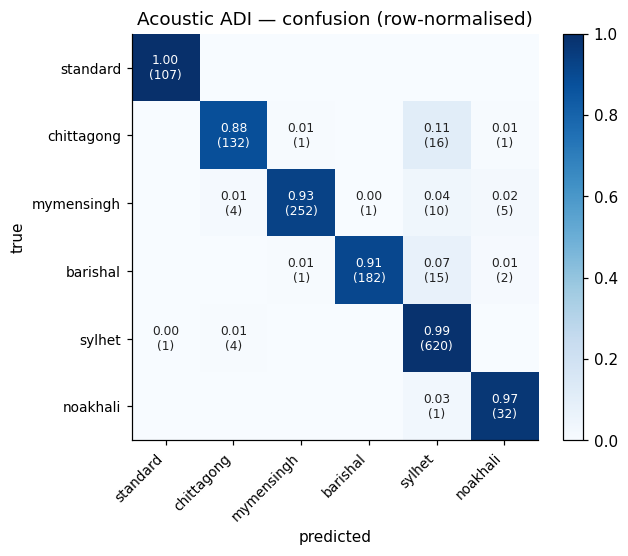

**tables/acoustic_per_class.csv** &nbsp; (6 rows)

,dialect,precision,recall,f1,support
0,standard,0.990741,1.000000,0.995349,107
1,chittagong,0.942857,0.880000,0.910345,150
2,mymensingh,0.992126,0.926471,0.958175,272
3,barishal,0.994536,0.910000,0.950392,200
4,sylhet,0.936556,0.992000,0.963481,625
5,noakhali,0.800000,0.969697,0.876712,33


**figures/10_acoustic_per_class.png**

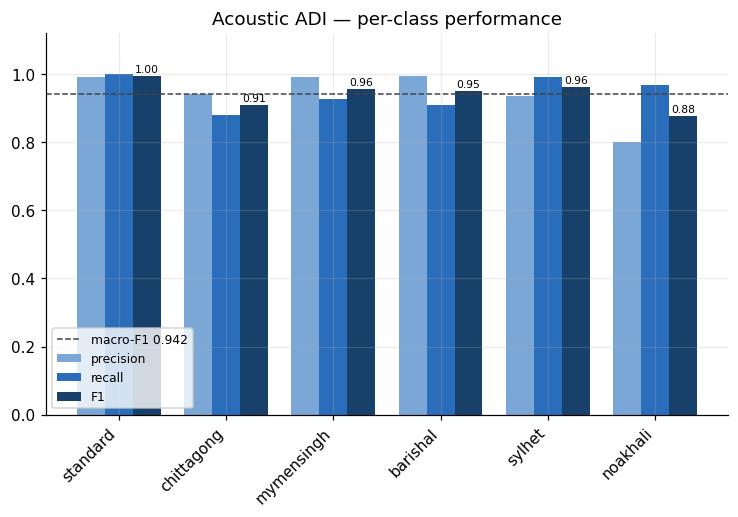

**tables/acoustic_vs_probe.csv** &nbsp; (4 rows)

,system,accuracy,macro_f1
0,chance,0.166667,0.166667
1,shortcut probe,0.733958,0.613754
2,acoustic (XLS-R),0.955299,0.942409
3,gain over probe,0.221341,0.328655


**figures/11_acoustic_vs_probe.png**

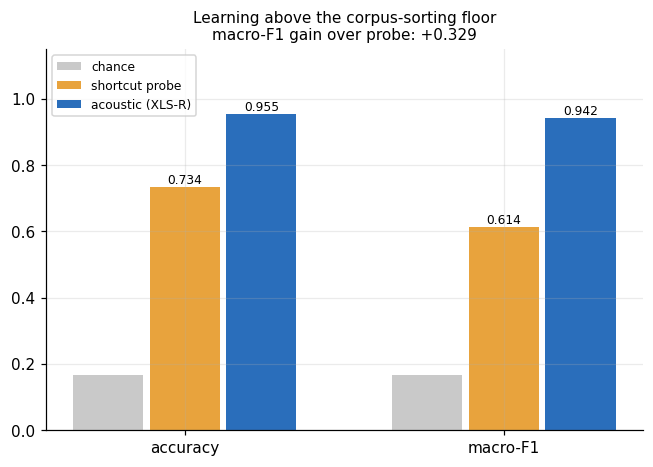

**tables/acoustic_confusions_ranked.csv** &nbsp; (13 rows)

,true,predicted,count
0,chittagong,sylhet,16
1,barishal,sylhet,15
2,mymensingh,sylhet,10
3,mymensingh,noakhali,5
4,mymensingh,chittagong,4
5,sylhet,chittagong,4
6,barishal,noakhali,2
7,chittagong,mymensingh,1
8,chittagong,noakhali,1
9,mymensingh,barishal,1


**figures/12_acoustic_confusions.png**

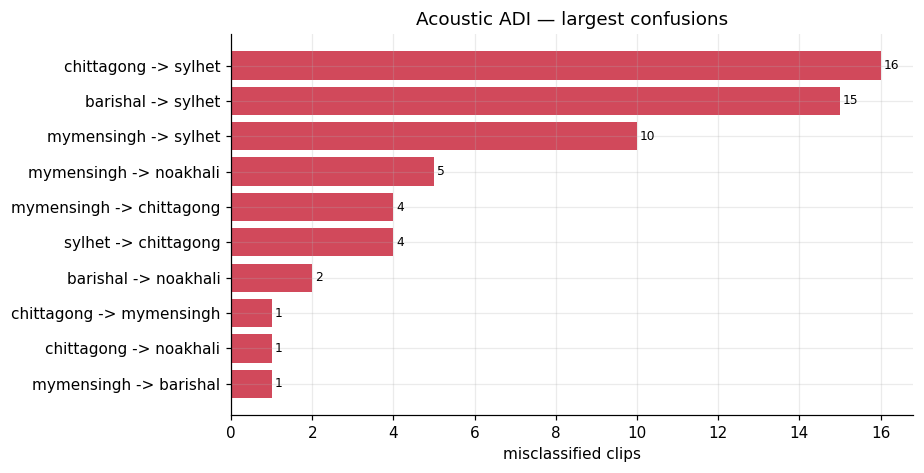

**tables/acoustic_summary.csv** &nbsp; (9 rows)

,metric,value
0,test_clips,1387
1,accuracy,0.9553
2,macro_f1,0.9424
3,chance,0.1667
4,probe_macro_f1,0.6138
5,gain_over_probe_macro_f1,0.3287
6,best_class,standard (0.995)
7,worst_class,noakhali (0.877)
8,worst_class_support,33



  test_clips                   1387
  accuracy                     0.9553
  macro_f1                     0.9424
  chance                       0.1667
  probe_macro_f1               0.6138
  gain_over_probe_macro_f1     0.3287
  best_class                   standard (0.995)
  worst_class                  noakhali (0.877)
  worst_class_support          33


<Figure size 704x528 with 0 Axes>

In [15]:
%cd /kaggle/working
%run plot_03_acoustic.py

## B3 — training curves

/kaggle/working


**tables/curve_acoustic.csv** &nbsp; (97 rows)

,epoch,step,loss,learning_rate,eval_loss,eval_accuracy,eval_macro_f1
0,0.184332,20,1.7907,0.000012,NaN,NaN,NaN
1,0.368664,40,1.7863,0.000024,NaN,NaN,NaN
2,0.552995,60,1.7768,0.000036,NaN,NaN,NaN
3,0.737327,80,1.7589,0.000048,NaN,NaN,NaN
4,0.921659,100,1.6487,0.000060,NaN,NaN,NaN
5,1.000000,109,NaN,NaN,1.438922,0.439500,0.356716
6,1.101382,120,1.4253,0.000073,NaN,NaN,NaN
7,1.285714,140,1.3667,0.000085,NaN,NaN,NaN
8,1.470046,160,1.3281,0.000097,NaN,NaN,NaN
9,1.654378,180,1.1094,0.000099,NaN,NaN,NaN


*...82 more rows in the CSV*

**figures/13_curve_acoustic_loss.png**

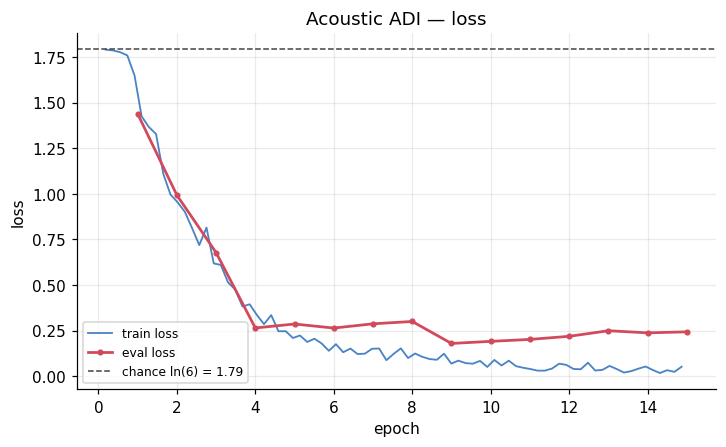

**figures/14_curve_acoustic_metrics.png**

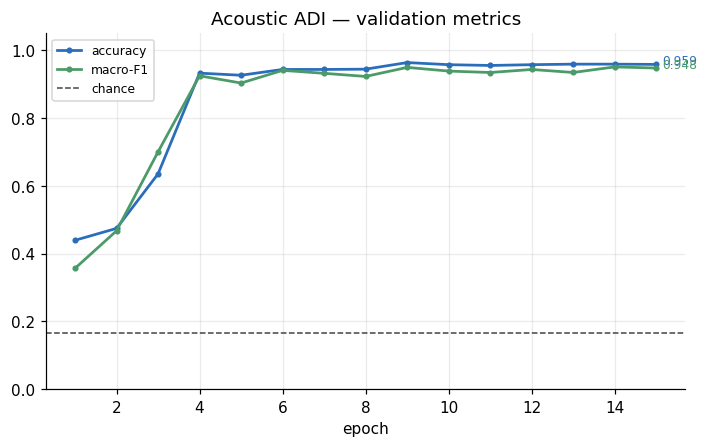


acoustic     best val macro-F1 0.9513 @ epoch 14.0


<Figure size 704x528 with 0 Axes>

In [16]:
%cd /kaggle/working
%run plot_04_curves.py

# B4 — acoustic: dump probabilities 

In [17]:
%cd /kaggle/working
%run 05_acoustic_probs.py

/kaggle/working
GPU 0: Tesla T4, 15.6 GB
GPU 1: Tesla T4, 15.6 GB
  200/1387
  400/1387
  600/1387
  800/1387
  1000/1387
  1200/1387

ACOUSTIC  acc 0.9553  macro-F1 0.9424
saved -> /kaggle/working/probs_acoustic.npz


# B5 — phonotactic: train 

Quantizes audio into discrete units and classifies the token sequence. Acoustic
detail is discarded; only sound ORDER survives.

N.B.: Notebook tried to allocate more memory than is available. So it got restarted midway thus train, validation and tests are cached.


In [1]:
%cd /kaggle/working
%run 06_train_phonotactic.py

/kaggle/working
GPU 0: Tesla T4, 15.6 GB
GPU 1: Tesla T4, 15.6 GB
train: cached
val: cached
test: cached
k-means fitted on 300000 frames -> 200 units
mean unit-sequence length: 284

PHONOTACTIC (n-gram)  acc 0.8234  macro-F1 0.7147
              precision    recall  f1-score   support

    standard       0.93      0.98      0.95       107
  chittagong       0.63      0.63      0.63       150
  mymensingh       0.90      0.87      0.89       272
    barishal       0.71      0.62      0.66       200
      sylhet       0.85      0.92      0.89       625
    noakhali       0.50      0.18      0.27        33

    accuracy                           0.82      1387
   macro avg       0.75      0.70      0.71      1387
weighted avg       0.82      0.82      0.82      1387

  standard     top units: u151, u82 u151, u42, u138, u47, u47 u195
  chittagong   top units: u38, u131 u194, u128 u28, u38 u155, u114 u132, u131
  mymensingh   top units: u104, u102, u127, u8, u104 u24, u25
  barishal     top

/kaggle/working/06_train_phonotactic.py:182: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.enc = nn.TransformerEncoder(enc, n_layers)


  ep  1  loss 1.7160  val macro-F1 0.4134
  ep  2  loss 1.2800  val macro-F1 0.5127
  ep  3  loss 0.9875  val macro-F1 0.6087
  ep  4  loss 0.8415  val macro-F1 0.6976
  ep  5  loss 0.7444  val macro-F1 0.7028
  ep  6  loss 0.6416  val macro-F1 0.7069
  ep  7  loss 0.6059  val macro-F1 0.7350
  ep  8  loss 0.5373  val macro-F1 0.7674
  ep  9  loss 0.4960  val macro-F1 0.7744
  ep 10  loss 0.4645  val macro-F1 0.7292
  ep 11  loss 0.4272  val macro-F1 0.7698
  ep 12  loss 0.4044  val macro-F1 0.7081
  ep 13  loss 0.3797  val macro-F1 0.7646
  ep 14  loss 0.3364  val macro-F1 0.7667
  ep 15  loss 0.3222  val macro-F1 0.7610
  ep 16  loss 0.2923  val macro-F1 0.7650
  ep 17  loss 0.2821  val macro-F1 0.7957
  ep 18  loss 0.2626  val macro-F1 0.7933
  ep 19  loss 0.2305  val macro-F1 0.7970
  ep 20  loss 0.2234  val macro-F1 0.7927
  ep 21  loss 0.2176  val macro-F1 0.8045
  ep 22  loss 0.1935  val macro-F1 0.8133
  ep 23  loss 0.1885  val macro-F1 0.8065
  ep 24  loss 0.1890  val macro-F1

# B6 — lexical: train 

In [2]:
%cd /kaggle/working
%run 07_train_lexical.py --source gold

/kaggle/working
GPU 0: Tesla T4, 15.6 GB
GPU 1: Tesla T4, 15.6 GB
text source: gold
train 6942  val 1281  test 1387
per dialect (test): {'chittagong': 150, 'sylhet': 625, 'standard': 107, 'mymensingh': 272, 'barishal': 200, 'noakhali': 33}

LEXICAL (char n-gram)  acc 0.9618  macro-F1 0.9476
              precision    recall  f1-score   support

    standard       0.81      1.00      0.90       107
  chittagong       1.00      0.99      1.00       150
  mymensingh       0.95      0.97      0.96       272
    barishal       0.99      0.90      0.94       200
      sylhet       0.98      0.97      0.98       625
    noakhali       1.00      0.85      0.92        33

    accuracy                           0.96      1387
   macro avg       0.96      0.95      0.95      1387
weighted avg       0.97      0.96      0.96      1387

  standard    : , য়, প, প, তিনি, তিনি
  chittagong  : ন, ঁ, ়্, য়্য, য়্, ়্য
  mymensingh  : ?, ?, এই, এই, কি, া?
  barishal    : হে, হে, মো, প, প, গো
  sylhet    

tokenizer_config.json:   0%|          | 0.00/119 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/586 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/443M [00:00<?, ?B/s]

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at csebuetnlp/banglabert and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


model.safetensors:   0%|          | 0.00/443M [00:00<?, ?B/s]

  ep 1  loss 0.7431  val macro-F1 0.8983
  ep 2  loss 0.1961  val macro-F1 0.9089
  ep 3  loss 0.0946  val macro-F1 0.9257
  ep 4  loss 0.0469  val macro-F1 0.9192
  ep 5  loss 0.0297  val macro-F1 0.9341
  ep 6  loss 0.0174  val macro-F1 0.9352

LEXICAL (BanglaBERT)  acc 0.9517  macro-F1 0.9177
              precision    recall  f1-score   support

    standard       0.96      0.99      0.98       107
  chittagong       0.96      0.99      0.97       150
  mymensingh       0.86      0.97      0.91       272
    barishal       0.99      0.81      0.89       200
      sylhet       1.00      0.98      0.99       625
    noakhali       0.74      0.79      0.76        33

    accuracy                           0.95      1387
   macro avg       0.92      0.92      0.92      1387
weighted avg       0.96      0.95      0.95      1387


using char_ngram as the lexical tier
saved -> /kaggle/working/probs_lexical_gold.npz


# B7 — compare the three ways + fuse

The per-dialect table is the finding: a dialect strongest on lexical has
diverged in **vocabulary**; strongest on acoustic means it differs mainly in
**accent**.

/kaggle/working
clips shared by all tiers: 1387

system                         accuracy   macro-F1
acoustic                         0.9553     0.9424
phonotactic                      0.8284     0.7517
lexical                          0.9618     0.9476
------------------------------------------------------------------
FUSE acoustic + phonotactic + lexical     0.9683     0.9563
FUSE acoustic + lexical          0.9640     0.9543
FUSE acoustic + phonotactic      0.9531     0.9289
FUSE phonotactic + lexical       0.9358     0.8892

per-dialect F1 by tier
dialect           acoustic  phonotactic      lexical
----------------------------------------------------
standard             0.995        0.949        0.895
chittagong           0.910        0.618        0.997
mymensingh           0.958        0.911        0.960
barishal             0.950        0.715        0.940
sylhet               0.963        0.882        0.976
noakhali             0.877        0.435        0.918

interpretation per

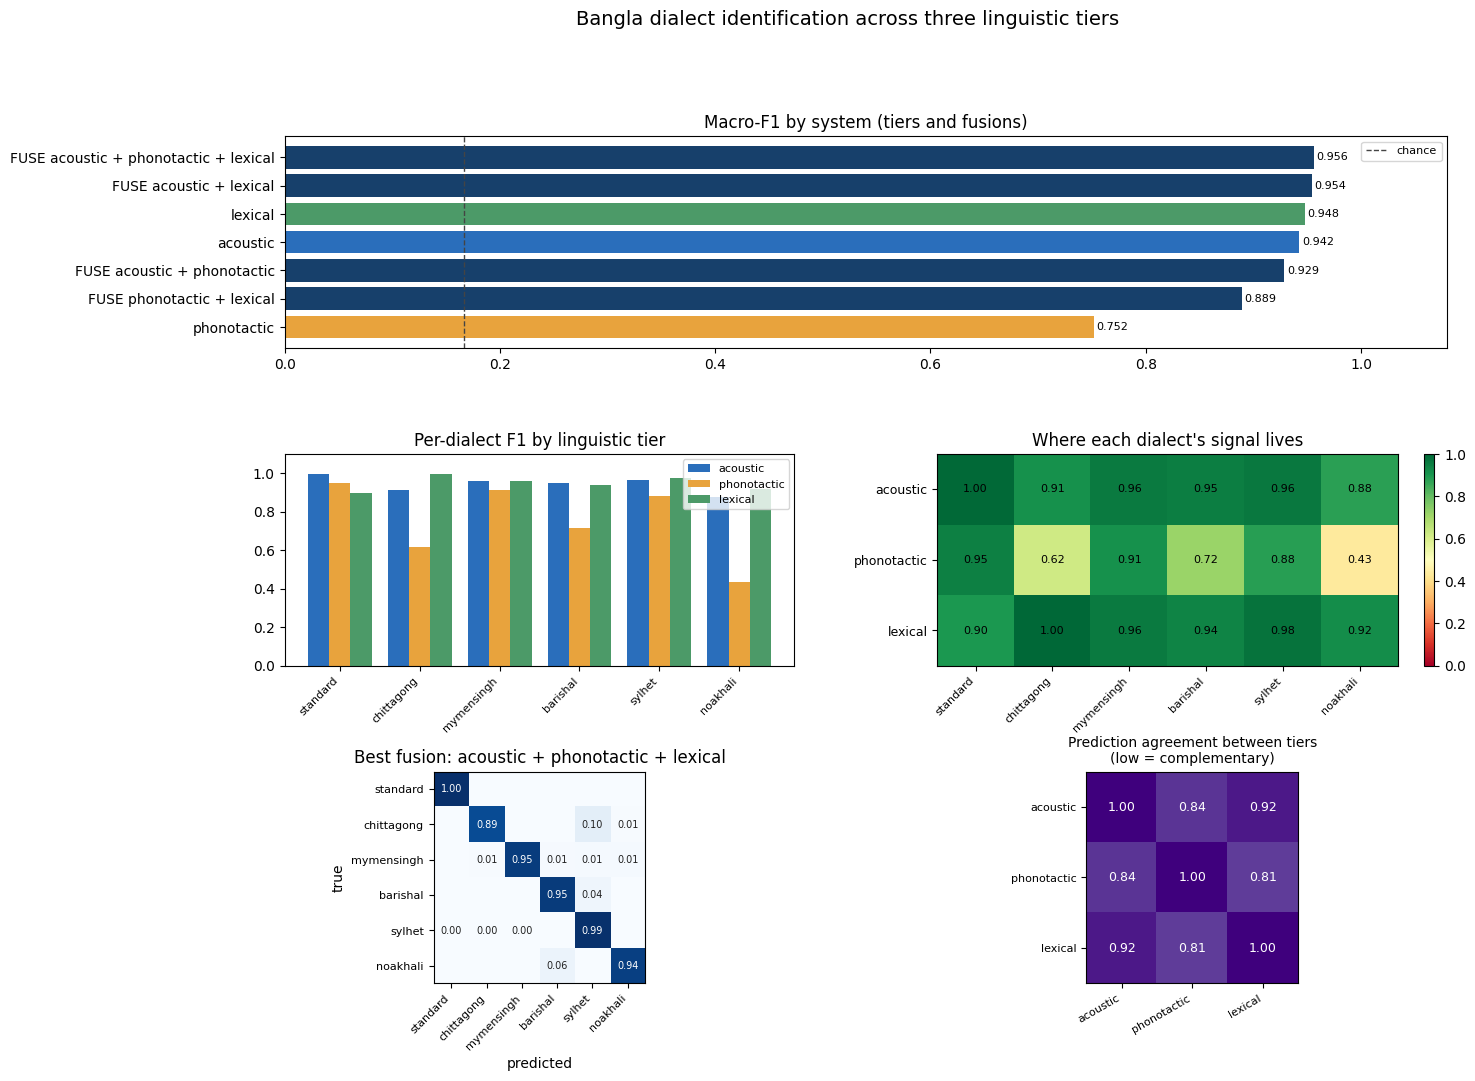


saved -> /kaggle/working/tier_comparison.json and tier_comparison.png


<Figure size 640x480 with 0 Axes>

In [3]:
%cd /kaggle/working
%run 08_compare_fusion.py

/kaggle/working
clips shared by all tiers: 1387


**tables/tier_all_systems.csv** &nbsp; (7 rows)

,system,type,accuracy,macro_f1
0,acoustic + phonotactic + lexical,fusion,0.968277,0.956278
1,acoustic + lexical,fusion,0.963951,0.954296
2,lexical,single,0.961788,0.947583
3,acoustic,single,0.955299,0.942409
4,acoustic + phonotactic,fusion,0.953136,0.928871
5,phonotactic + lexical,fusion,0.935833,0.889218
6,phonotactic,single,0.828407,0.751672


**figures/18_tier_all_systems.png**

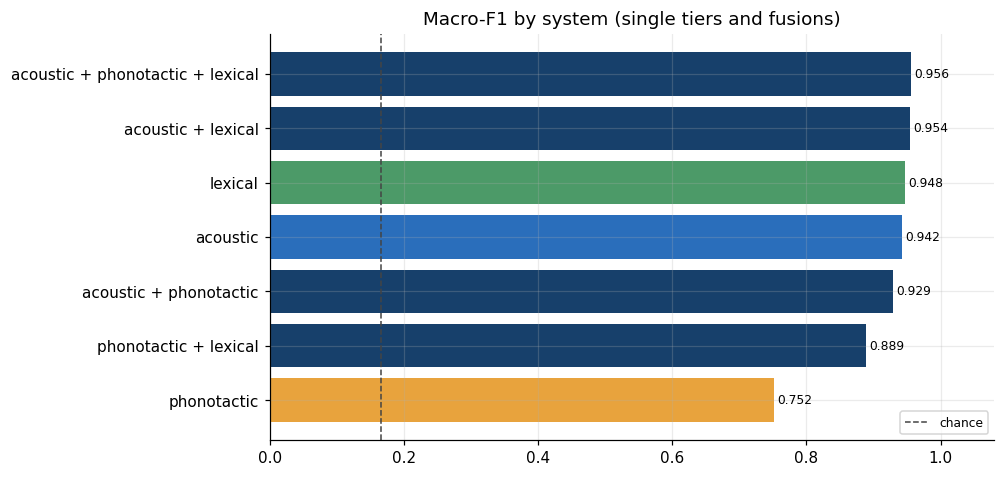

**tables/tier_per_dialect.csv** &nbsp; (6 rows)

,dialect,acoustic,phonotactic,lexical,best_tier,interpretation
0,standard,0.995349,0.948837,0.895397,acoustic,differs mainly in ACCENT (phonetic)
1,chittagong,0.910345,0.618297,0.996656,lexical,differs in VOCABULARY / morphology
2,mymensingh,0.958175,0.911111,0.959854,lexical,differs in VOCABULARY / morphology
3,barishal,0.950392,0.715405,0.939633,acoustic,differs mainly in ACCENT (phonetic)
4,sylhet,0.963481,0.881600,0.975923,lexical,differs in VOCABULARY / morphology
5,noakhali,0.876712,0.434783,0.918033,lexical,differs in VOCABULARY / morphology


**figures/19_tier_per_dialect.png**

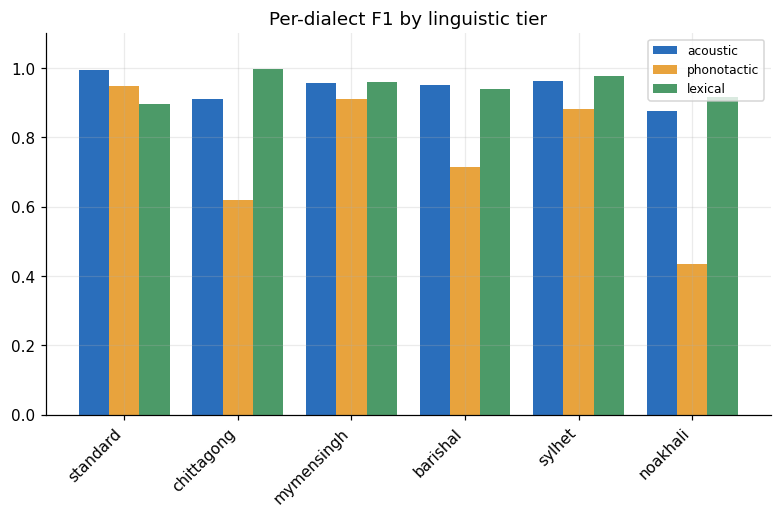

**tables/tier_per_dialect_matrix.csv** &nbsp; (3 rows)

,standard,chittagong,mymensingh,barishal,sylhet,noakhali
acoustic,0.9953,0.9103,0.9582,0.9504,0.9635,0.8767
phonotactic,0.9488,0.6183,0.9111,0.7154,0.8816,0.4348
lexical,0.8954,0.9967,0.9599,0.9396,0.9759,0.9180


**figures/20_tier_heatmap.png**

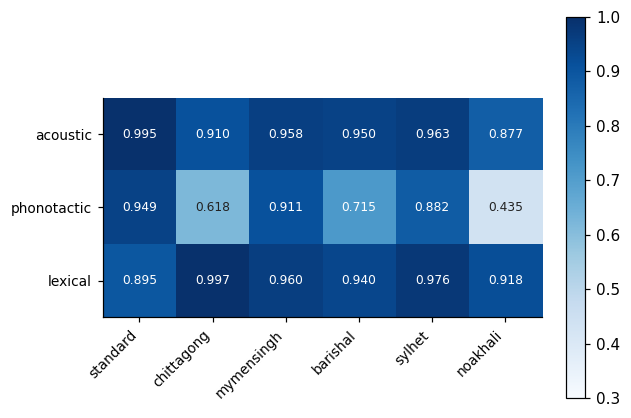

**tables/tier_best_fusion_confusion.csv** &nbsp; (6 rows)

,standard,chittagong,mymensingh,barishal,sylhet,noakhali
standard,107,0,0,0,0,0
chittagong,0,134,0,0,15,1
mymensingh,0,2,259,3,4,4
barishal,0,0,0,191,9,0
sylhet,1,2,1,0,621,0
noakhali,0,0,0,2,0,31


**figures/21_tier_fusion_confusion.png**

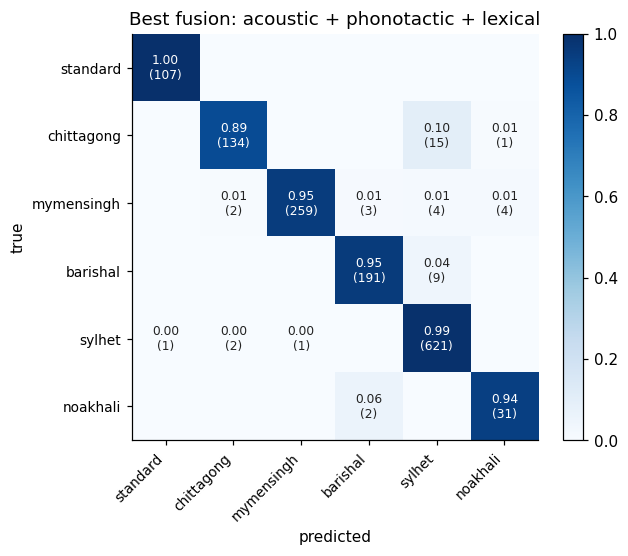

**tables/tier_agreement.csv** &nbsp; (3 rows)

,acoustic,phonotactic,lexical
acoustic,1.0000,0.8356,0.9193
phonotactic,0.8356,1.0000,0.8097
lexical,0.9193,0.8097,1.0000


**figures/22_tier_agreement.png**

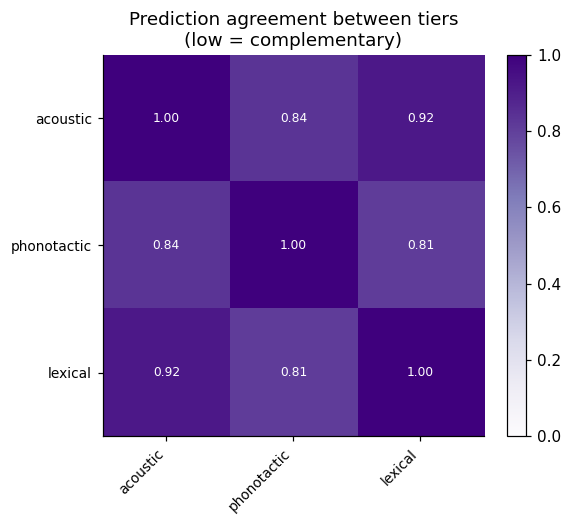


per-dialect verdict:
  standard      best = acoustic     -> differs mainly in ACCENT (phonetic)
  chittagong    best = lexical      -> differs in VOCABULARY / morphology
  mymensingh    best = lexical      -> differs in VOCABULARY / morphology
  barishal      best = acoustic     -> differs mainly in ACCENT (phonetic)
  sylhet        best = lexical      -> differs in VOCABULARY / morphology
  noakhali      best = lexical      -> differs in VOCABULARY / morphology


<Figure size 704x528 with 0 Axes>

In [4]:
%cd /kaggle/working
%run plot_05_comparison.py

## B8 — curves again (adds the phonotactic panel)

/kaggle/working


**tables/curve_acoustic.csv** &nbsp; (97 rows)

,epoch,step,loss,learning_rate,eval_loss,eval_accuracy,eval_macro_f1
0,0.184332,20,1.7907,0.000012,NaN,NaN,NaN
1,0.368664,40,1.7863,0.000024,NaN,NaN,NaN
2,0.552995,60,1.7768,0.000036,NaN,NaN,NaN
3,0.737327,80,1.7589,0.000048,NaN,NaN,NaN
4,0.921659,100,1.6487,0.000060,NaN,NaN,NaN
5,1.000000,109,NaN,NaN,1.438922,0.439500,0.356716
6,1.101382,120,1.4253,0.000073,NaN,NaN,NaN
7,1.285714,140,1.3667,0.000085,NaN,NaN,NaN
8,1.470046,160,1.3281,0.000097,NaN,NaN,NaN
9,1.654378,180,1.1094,0.000099,NaN,NaN,NaN


*...82 more rows in the CSV*

**figures/13_curve_acoustic_loss.png**

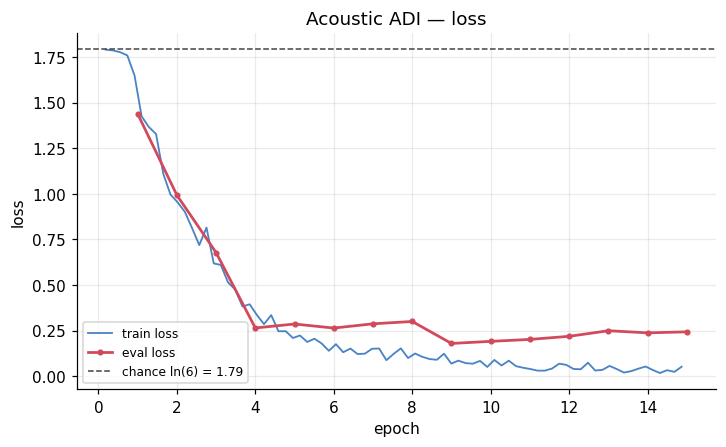

**figures/14_curve_acoustic_metrics.png**

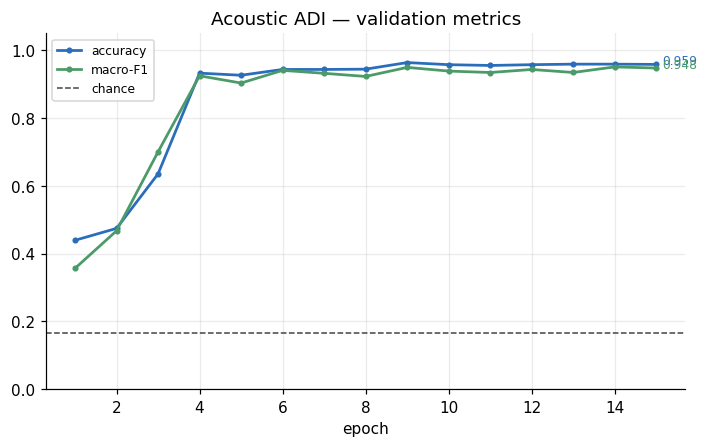

**tables/curve_phonotactic.csv** &nbsp; (25 rows)

,epoch,train_loss,val_macro_f1
0,1,1.715978,0.413443
1,2,1.279996,0.512739
2,3,0.987531,0.608678
3,4,0.841479,0.697583
4,5,0.744366,0.702755
5,6,0.641613,0.706884
6,7,0.605894,0.735019
7,8,0.537275,0.767439
8,9,0.496044,0.774380
9,10,0.464463,0.729211


*...10 more rows in the CSV*

**figures/17_curve_phonotactic.png**

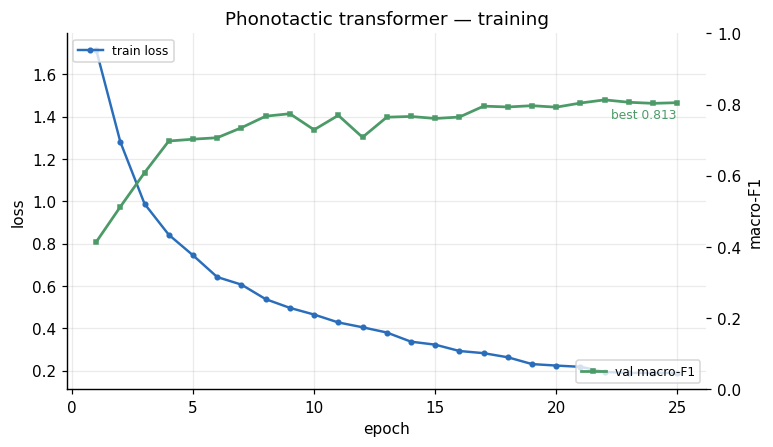


acoustic     best val macro-F1 0.9513 @ epoch 14.0
phonotactic  best val macro-F1 0.8133


<Figure size 704x528 with 0 Axes>

In [5]:
%cd /kaggle/working
%run plot_04_curves.py

## Collecting outputs

In [ ]:
import glob, os
print("FIGURES"); [print("  ", os.path.basename(f)) for f in sorted(glob.glob("/kaggle/working/figures/*.png"))]
print("TABLES");  [print("  ", os.path.basename(f)) for f in sorted(glob.glob("/kaggle/working/tables/*.csv"))]
!cd /kaggle/working && zip -qr outputs.zip figures tables *.json 2>/dev/null
print("\n-> /kaggle/working/outputs.zip")